<a href="https://colab.research.google.com/github/Marcoventimiglia07/Frontend/blob/main/Progetto_Data_Analysis_Completo_IT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 0. Setup e caricamento dei dati

**0.1 Importazione da Drive:** montiamo Google Drive per leggere i file del progetto.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**0.2 Setup:** import, caricamento dati, costanti e colori in un'unica cella: tutte le celle successive usano questi riferimenti.

In [ ]:
# --- Imports ---
import json
import re

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import Patch

import folium
from folium.plugins import HeatMap

from IPython.display import display
from google.colab import data_table
#data_table.enable_dataframe_formatter()

import seaborn as sns

# --- Load listings ---
listings = pd.read_csv("/content/drive/MyDrive/Dataset Progetto SJA/listings.csv")

# --- Catania working dataset ---
cols_to_drop = [
    "source","listing_url","scrape_id","last_scraped","picture_url",
    "host_id","host_url","host_name","host_since",'host_picture_url',
    "host_about","host_response_time","host_response_rate",'host_has_profile_pic',
    "minimum_minimum_nights", "maximum_minimum_nights",
    "minimum_maximum_nights", "maximum_maximum_nights",
]

listings_catania = (
    listings[listings["neighbourhood_cleansed"] == "Catania"]
    .dropna(axis=1, how="all")                                         # drop fully empty columns
    .drop(columns=cols_to_drop, errors="ignore")                       # drop unused columns
    .loc[:, lambda d: ~d.columns.str.startswith("price_quote_")]       # drop price_quote_* columns
    .copy()
)

# --- Price cleaning ---
listings_catania["price"] = pd.to_numeric(
    listings_catania["price"].astype(str).str.replace(r"[$,]", "", regex=True),
    errors="coerce",
)

# --- Dates ---
listings_catania["first_review"] = pd.to_datetime(listings_catania["first_review"])
listings_catania["last_review"] = pd.to_datetime(listings_catania["last_review"])

# --- Constants ---
CENTER_LAT = 37.5026       # Piazza Duomo
CENTER_LON = 15.0872       # Piazza Duomo
RADIUS_KM = 1.5            # around Piazza Duomo
PRICE_CAP = 494.64         # about the 99th percentile (494.64)

listings_catania["price_outlier"] = listings_catania["price"] > PRICE_CAP

# --- Distance (haversine formula) ---
def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0  # Earth radius in km
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = (np.sin((lat2 - lat1) / 2) ** 2
         + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2)
    return 2 * R * np.arcsin(np.sqrt(a))

# --- Palette Minimalista ---
COLOR_RED = "#E45756"
COLOR_BLUE = "#4C78A8"
COLOR_YELLOW = "#E5BE01"

# --- Italian display names (used only for chart labels; data keys stay unchanged) ---
IT_CLASS = {"small": "Piccoli", "medium": "Medi", "large": "Grandi"}
IT_CLASS_GUESTS = {"small": "Piccoli (1-2 ospiti)", "medium": "Medi (3-4 ospiti)", "large": "Grandi (5+ ospiti)"}
IT_ROOM = {"Entire home/apt": "Casa intera", "Private room": "Camera privata",
           "Hotel room": "Camera d'hotel", "Shared room": "Camera condivisa"}
IT_LOC = {"Center": "Centro", "Outside Center": "Fuori centro"}
IT_BAND = {"budget": "Economica", "mid": "Media", "expensive": "Costosa"}
IT_PROP = {
    "Entire rental unit": "Appartamento intero in affitto",
    "Private room in rental unit": "Camera privata in appartamento",
    "Entire home": "Casa intera",
    "Entire condo": "Condominio intero",
    "Entire loft": "Loft intero",
    "Entire villa": "Villa intera",
    "Entire serviced apartment": "Appartamento intero con servizi",
    "Entire guest suite": "Suite intera per ospiti",
    "Entire guesthouse": "Dépendance intera",
    "Entire townhouse": "Casa a schiera intera",
    "Entire bed and breakfast": "B&B intero",
    "Private room in home": "Camera privata in casa",
    "Private room in condo": "Camera privata in condominio",
    "Private room in loft": "Camera privata in loft",
    "Private room in villa": "Camera privata in villa",
    "Private room in guest suite": "Camera privata in suite",
    "Private room in bed and breakfast": "Camera privata in B&B",
    "Room in bed and breakfast": "Camera in B&B",
    "Room in hotel": "Camera in hotel",
    "Room in boutique hotel": "Camera in boutique hotel",
    "Other": "Altro",
}
IT_AMENITY = {"Wi-Fi": "Wi-Fi", "Air conditioning": "Aria condizionata", "Kitchen": "Cucina",
              "Washer": "Lavatrice", "Parking (any)": "Parcheggio (gratuito o a pagamento)",
              "Free parking": "Parcheggio gratuito", "Pool": "Piscina",
              "Sea view": "Vista mare", "Self check-in": "Self check-in (arrivo autonomo)"}

In [ ]:
# se vogliamo stampare tutti i record e le colonne STAMPIAMO TUTTO CA**O
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)

In [ ]:
listings.head()

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,host_url,host_profile_id,host_profile_url,host_name,host_since,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,host_location,host_about,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_thumbnail_url,host_picture_url,host_neighbourhood,host_listings_count,host_total_listings_count,host_verifications,host_has_profile_pic,host_identity_verified,neighbourhood,neighbourhood_cleansed,neighbourhood_group_cleansed,latitude,longitude,property_type,room_type,accommodates,bathrooms,bathrooms_text,bedrooms,beds,amenities,price,price_quote_checkin_date,price_quote_checkout_date,price_quote_total_price,price_quote_price_per_night,price_quote_raw,minimum_nights,maximum_nights,minimum_minimum_nights,maximum_minimum_nights,minimum_maximum_nights,maximum_maximum_nights,minimum_nights_avg_ntm,maximum_nights_avg_ntm,calendar_updated,has_availability,availability_30,availability_60,availability_90,availability_365,calendar_last_scraped,number_of_reviews,number_of_reviews_ltm,number_of_reviews_l30d,availability_eoy,number_of_reviews_ly,estimated_occupancy_l365d,estimated_revenue_l365d,first_review,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,3902766,https://www.airbnb.com/rooms/3902766,20260925011213,2026-09-27,NaN,Palazzo Santamaria,"The accommodation, fully furnished, equipped a...",NaN,https://a0.muscache.com/pictures/105811706/0dd...,20209995,https://www.airbnb.com/users/show/20209995,1462612191853371018,https://www.airbnb.com/users/profile/146261219...,Nicoletta,NaN,12,1,12,1,"Lentini, Italy",La Sicilia merita di essere conosciuta e visit...,NaN,NaN,NaN,f,NaN,https://a0.muscache.com/im/pictures/user/ede95...,NaN,2,NaN,NaN,t,t,NaN,Augusta,NaN,37.32296,15.09520,Entire rental unit,Entire home/apt,6,NaN,1 bath,2.0,5.0,"[""Single level home"", ""Extra pillows and blank...",$94.75,2026-09-30,2026-10-04,379.0,94.75,"{""quote"": {""taxes"": null, ""currency"": ""EUR"", ""...",4.0,1125.0,4.0,4.0,1125.0,1125.0,4.0,1125.0,NaN,t,16,38,68,343,2026-09-27,69,3,1,74,4,24,2274.0,2015-06-20,2026-09-19,4.72,4.75,4.78,4.93,4.84,4.57,4.68,IT089001C2MQPOIHRH,NaN,1,1,0,0,0.50
1,3905734,https://www.airbnb.com/rooms/3905734,20260925011213,2026-09-27,NaN,relax on the sea Southern coast sicily house,"Apartment in a villa by the sea of Sicily , ve...",NaN,https://a0.muscache.com/pictures/84932327/3b8b...,20227654,https://www.airbnb.com/users/show/20227654,1462612248216633928,https://www.airbnb.com/users/profile/146261224...,Massimo,NaN,12,1,12,1,"Gela, Italy",Amante del mare e della natura.,NaN,NaN,NaN,f,NaN,https://a0.muscache.com/im/pictures/user/User-...,NaN,2,NaN,NaN,t,f,NaN,Gela,NaN,37.10300,14.13028,Entire condo,Entire home/apt,4,NaN,1 bath,1.0,3.0,"[""Single level home"", ""Extra pillows and blank...",$238.00,2026-10-04,2026-10-05,238.0,238.00,"{""quote"": {""taxes"": null, ""currency"": ""EUR"", ""...",1.0,1125.0,1.0,1.0,1125.0,1125.0,1.0,1125.0,NaN,t,23,53,83,358,2026-09-27,4,0,0,89,0,0,0.0,2015-08-07,2023-08-25,4.50,4.50,4.50,5.00,4.75,4.75,4.50,IT085007C2ZXXPS8HT,NaN,2,2,0,0,0.03
2,3905745,https://www.airbnb.com/rooms/3905745,20260925011213,2026-09-28,NaN,Firriato 2,"Apartment of 60 square meters, recently renova...",NaN,https://a0.muscache.com/pictures/85758259/25c2...,20014469,https://www.airbnb.com/users/show/20014469,1463096864511065515,https://www.airbnb.com/users/profile/146309686...,Francesco,NaN,12,1,12,1,"Palermo, Italy",NaN,NaN,NaN,NaN,t,NaN,https://a0.muscache.com/im/users/20014469/prof...,NaN,2,NaN,NaN,t,t,NaN,Palermo,NaN,38.12

**0.3 Controllo del dataset caricato:** andiamo perciò a vedere se le modifiche sono state apportate correttamente.

In [ ]:
listings_catania.head()

,id,name,description,host_profile_id,host_profile_url,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,host_location,host_is_superhost,host_listings_count,host_identity_verified,neighbourhood_cleansed,latitude,longitude,property_type,room_type,accommodates,bathrooms_text,bedrooms,beds,amenities,price,minimum_nights,maximum_nights,minimum_nights_avg_ntm,maximum_nights_avg_ntm,has_availability,availability_30,availability_60,availability_90,availability_365,calendar_last_scraped,number_of_reviews,number_of_reviews_ltm,number_of_reviews_l30d,availability_eoy,number_of_reviews_ly,estimated_occupancy_l365d,estimated_revenue_l365d,first_review,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month,price_outlier
26,7569307,3 deluxe trinacria view,The property has been completely renovated. Ea...,1462659819828353767,https://www.airbnb.com/users/profile/146265981...,11,4,11,2,"Catania, Italy",f,5,t,Catania,37.49784,15.08634,Private room in rental unit,Private room,2,1 private bath,1.0,1.0,"[""Single level home"", ""Fire extinguisher"", ""Ex...",100.33,3.0,1125.0,3.0,1125.0,t,8,38,68,342,2026-09-28,311,0,0,73,0,0,0.0,2015-08-09,2023-10-20,4.90,4.88,4.94,4.98,4.98,4.88,4.84,IT087015C1E8Q23SXR,5,0,5,0,2.29,False
34,7576432,2 suite trinacria view,Totally renovated property. <br />Each room ha...,1462659819828353767,https://www.airbnb.com/users/profile/146265981...,11,4,11,2,"Catania, Italy",f,5,t,Catania,37.49822,15.08520,Private room in rental unit,Private room,3,1 private bath,1.0,2.0,"[""Fire extinguisher"", ""Extra pillows and blank...",93.00,2.0,1125.0,2.0,1125.0,t,11,41,71,346,2026-09-28,4,0,0,76,0,0,0.0,2017-07-15,2024-08-17,5.00,5.00,5.00,5.00,5.00,4.75,5.00,IT087015C1E8Q23SXR,5,0,5,0,0.04,False
105,7643769,nice flat in catania city centre sea and Etna ...,"in the heart of Catania, viale Jonio 98, very ...",1462660871873989772,https://www.airbnb.com/users/profile/146266087...,13,8,11,1,"Caltanissetta, Italy",f,1,t,Catania,37.51371,15.10067,Entire rental unit,Entire home/apt,5,1 bath,2.0,4.0,"[""Essentials"", ""Elevator"", ""First aid kit"", ""T...",102.43,31.0,1125.0,31.0,1125.0,t,29,59,89,364,2026-09-28,1,0,0,94,0,0,0.0,2022-08-19,2022-08-19,5.00,5.00,5.00,5.00,5.00,5.00,3.00,NaN,1,1,0,0,0.02,False
117,135494,AMMIRAGLIA 140mq,My place is close to art and culture and resta...,1462513412843652116,https://www.airbnb.com/users/profile/146251341...,15,3,15,3,"Catania, Italy",f,5,t,Catania,37.50064,15.08520,Entire vacation home,Entire home/apt,8,2 baths,3.0,4.0,"[""Extra pillows and blankets"", ""Ethernet conne...",200.00,1.0,1125.0,1.0,1125.0,t,7,32,62,330,2026-09-28,119,13,0,67,23,78,15600.0,2019-02-03,2026-08-22,4.50,4.45,4.61,4.60,4.55,4.73,4.58,IT087015C2CIK6KZNS,5,3,2,0,1.28,False
118,136725,AMURI 40mq,AMURI is a cosy and intimate 40mq flat. Compos...,1462513412843652116,https://www.airbnb.com/users/profile/146251341...,15,3,15,3,"Catania, Italy",f,5,t,Catania,37.49924,15.08583,Private room in rental unit,Private room,4,1.5 baths,1.0,2.0,"[""Fire extinguisher"", ""Extra pillows and blank...",125.00,1.0,1125.0,1.0,1125.0,t,7,37,67,339,2026-09-28,205,0,0,72,0,0,0.0,2011-08-02,2024-10-14,4.82,4.85,4.88,4.93,4.90,4.84,4.80,IT087015C2CIK6KZNS,5,3,2,0,1.11,False


In [ ]:
print("Shape:", listings_catania.shape)

Shape: (4669, 57)


## 1.Controllo dei dati

**1.1 Controllo della colonna `price`:** la colonna `price` è una stringa (es. `"$100.33"`): abbiamo rimosso il simbolo `$` e la virgola delle migliaia e la convertiamo in numero nella prima cella di setup. Le colonne `price_quote_*` non servono: il prezzo per notte coincide con `price` e il totale dipende dalla durata del soggiorno simulato, quindi non è confrontabile tra annunci. Qui controlliamo quindi prezzi mancanti, prezzi uguali a 0 e percentili.

Prezzi mancanti: 385
Prezzi uguali a 0: 0

--- Statistiche Descrittive ---
count    4284.000000
mean      118.106422
std       124.071343
min        10.120000
25%        74.500000
50%        95.000000
75%       128.542500
max      5623.070000
Name: price, dtype: float64

--- Percentili per Outlier ---
0.900     181.95200
0.950     233.00000
0.990     494.64280
0.999    1125.05019
Name: price, dtype: float64


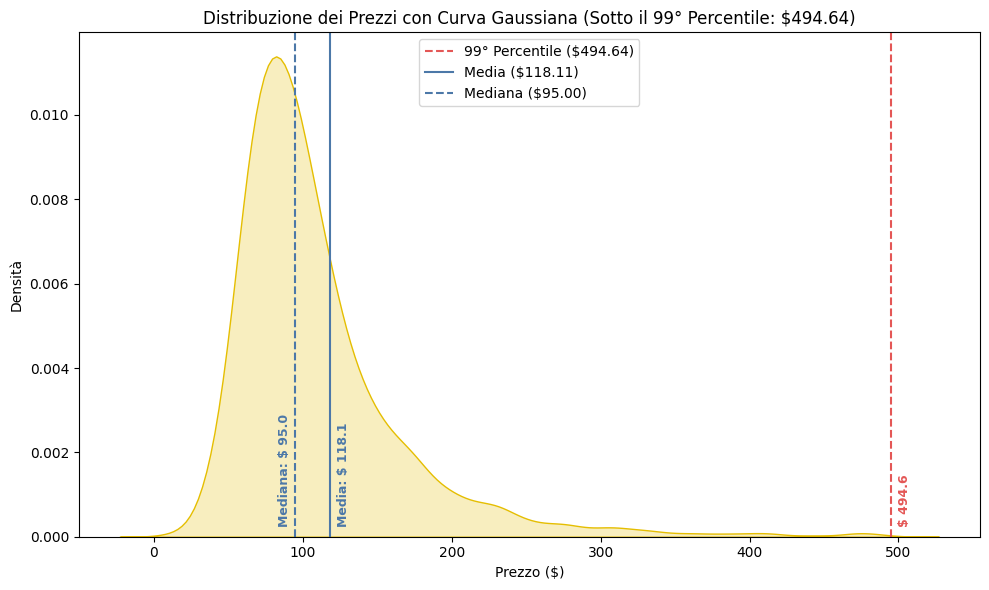

In [ ]:
# Controlli finali per decidere la soglia degli outlier (la pulizia di 'price' è nel setup)
print("Prezzi mancanti:", listings_catania["price"].isna().sum())
print("Prezzi uguali a 0:", (listings_catania["price"] == 0).sum())
print("\n--- Statistiche Descrittive ---")
print(listings_catania["price"].describe())
print("\n--- Percentili per Outlier ---")
p99 = listings_catania["price"].quantile(0.99)
print(listings_catania["price"].quantile([0.9, 0.95, 0.99, 0.999]))

# Calcoliamo media e mediana dei prezzi
mean_price = listings_catania["price"].mean()
median_price = listings_catania["price"].median()

# --- Visualizzazione Grafica dello Studio dei Prezzi ---
plt.figure(figsize=(10, 6))
# Curva KDE (gaussiana) limitata al 99° percentile senza le barre dell'istogramma
sns.kdeplot(listings_catania[listings_catania["price"] <= p99]["price"], fill=True, color=COLOR_YELLOW)

# Linee di riferimento per metriche di prezzo
plt.axvline(p99, color=COLOR_RED, linestyle="--", linewidth=1.5, label=f"99° Percentile (${p99:.2f})")
plt.axvline(mean_price, color=COLOR_BLUE, linestyle="-", linewidth=1.5, label=f"Media (${mean_price:.2f})")
plt.axvline(median_price, color=COLOR_BLUE, linestyle="--", linewidth=1.5, label=f"Mediana (${median_price:.2f})")

# Posizionamento dei valori sull'asse X per evitare sovrapposizioni
ax = plt.gca()
y_min, y_max = ax.get_ylim()

# Posizioniamo i testi vicino alla base dell'asse X (y = 2% dell'altezza massima)
text_y = y_max * 0.02

plt.text(p99 + 5, text_y, f"$ {p99:.1f}", color=COLOR_RED, fontweight="bold", fontsize=9, rotation=90, va="bottom")
plt.text(mean_price + 5, text_y, f"Media: $ {mean_price:.1f}", color=COLOR_BLUE, fontweight="bold", fontsize=9, rotation=90, va="bottom")
plt.text(median_price - 12, text_y, f"Mediana: $ {median_price:.1f}", color=COLOR_BLUE, fontweight="bold", fontsize=9, rotation=90, va="bottom")

plt.title(f"Distribuzione dei Prezzi con Curva Gaussiana (Sotto il 99° Percentile: ${p99:.2f})")
plt.xlabel("Prezzo ($)")
plt.ylabel("Densità")
plt.legend()
plt.tight_layout()
plt.show()

**1.2 Esplorazione della capacità delle strutture:** analizziamo le variabili legate alla capacità di accoglienza: numero massimo di ospiti (`accommodates`), camere (`bedrooms`) e posti letto (`beds`).

Ordinando il dataset in senso decrescente per `accommodates`, possiamo osservare le strutture più capienti e verificare la coerenza dei dati (ad esempio, individuare casi sospetti in cui un numero elevato di ospiti non è supportato da un numero adeguato di letti o camere).

=== TOP 10 STRUTTURE PIÙ CAPIENTI (Verifica Coerenza Dati) ===


,name,accommodates,bedrooms,beds,price
47321,Sikelia Palace apartments,16,5.0,14.0,382.00
17746,Dimora in palazzo nobiliare nel salotto di Cat...,16,6.0,NaN,NaN
52654,"Storico17Apartments for big groups, up to 20gu...",16,6.0,12.0,891.00
36082,Donna Fortuna,16,9.0,23.0,70.04
16945,ANTICHI SOFFITTI B&B CENTRO CITTA,16,5.0,5.0,400.83
10640,"""Mamma Mia!"" Palace - 18pax (City Center)",16,8.0,9.0,494.16
39264,Centrale luminoso con terrazza,16,5.0,7.0,168.26
10294,Intero Appartamento con terrazzo dietro al Duomo,16,6.0,14.0,289.50
13105,Bed&Breakfast Archimede Centro Storico di Catania,16,6.0,12.0,126.00
41191,TOP for groups and families in the center as h...,16,8.0,13.0,1358.50


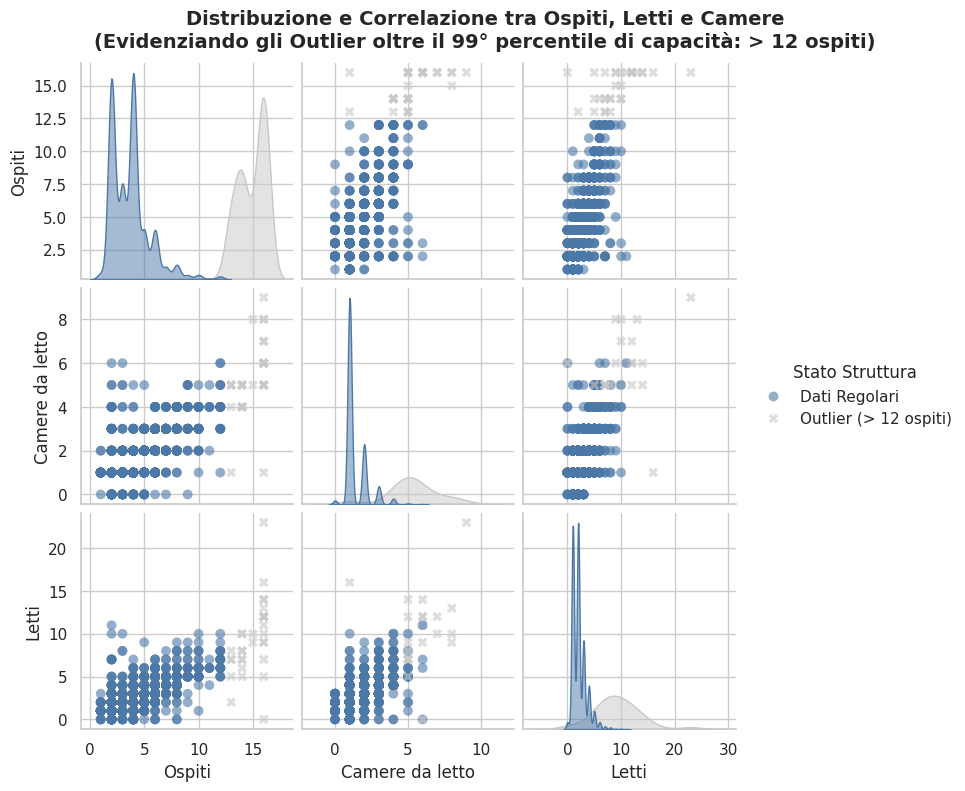

In [ ]:
# 1. Analisi Tabellare: Ordiniamo il dataset per verificare la coerenza delle strutture più grandi
print("=== TOP 10 STRUTTURE PIÙ CAPIENTI (Verifica Coerenza Dati) ===")
top_capienti = listings_catania[['name', 'accommodates', 'bedrooms', 'beds', 'price']].sort_values(by='accommodates', ascending=False).head(10)
display(top_capienti)

# 2. Analisi Grafica: Visualizzazione delle correlazioni e identificazione degli outlier
capacity_threshold = listings_catania['accommodates'].quantile(0.99)

# Creiamo una copia temporanea per la marcatura grafica degli outlier
plot_df = listings_catania[['accommodates', 'bedrooms', 'beds']].copy()
plot_df['beds'] = plot_df['beds'].fillna(0)  # Gestione dei valori mancanti
plot_df['Stato Struttura'] = np.where(
    plot_df['accommodates'] > capacity_threshold,
    f'Outlier (> {int(capacity_threshold)} ospiti)',
    'Dati Regolari'
)

# Impostiamo lo stile e la palette coerente con il brand del notebook
sns.set_theme(style="whitegrid")
custom_palette = {
    'Dati Regolari': COLOR_BLUE,
    f'Outlier (> {int(capacity_threshold)} ospiti)': '#C8C8C8'
}

# Nomi delle colonne in italiano per gli assi del pairplot
plot_df = plot_df.rename(columns={'accommodates': 'Ospiti', 'bedrooms': 'Camere da letto', 'beds': 'Letti'})

# Creiamo il pairplot
g = sns.pairplot(
    plot_df,
    hue='Stato Struttura',
    palette=custom_palette,
    markers=['o', 'X'],
    plot_kws={'alpha': 0.6, 's': 50, 'edgecolor': 'none'},
    diag_kws={'common_norm': False, 'alpha': 0.5}
)

g.fig.suptitle(
    f"Distribuzione e Correlazione tra Ospiti, Letti e Camere\n(Evidenziando gli Outlier oltre il 99° percentile di capacità: > {int(capacity_threshold)} ospiti)",
    y=1.05,
    fontsize=14,
    fontweight='bold'
)

plt.show()

### **Interpretazione del Grafico e dell'Analisi di Capacità**

L'analisi combinata della tabella delle 10 strutture più capienti e del grafico a matrice (*pairplot*) ci fornisce importanti informazioni sulla coerenza strutturale dei dati di Catania e sulle relazioni tra le tre variabili di capacità: **Ospiti (accommodates)**, **Letti (beds)** e **Camere da letto (bedrooms)**.

#### **1. Coerenza dei Dati e Strutture di Grandi Dimensioni (Top 10)**
* **Verifica Empirica:** La tabella mostra che le strutture con la massima capacità registrata accolgono fino a **16 ospiti**. Nella maggior parte dei casi, questi grandi numeri sono coerenti con la dotazione strutturale: ad esempio, *Sikelia Palace apartments* offre 14 letti in 5 camere, e *Donna Fortuna* offre ben 23 letti distribuiti in 9 camere.
* **Valori Mancanti e Anomalie:** Notiamo un caso particolare (*Dimora in palazzo nobiliare...*) che non presenta dati per letti e prezzo (`NaN`), il che giustifica la necessità delle nostre operazioni di pulizia e imputazione dei dati (come il riempimento dei valori mancanti con `fillna(0)` effettuato nel codice).

#### **2. Relazioni e Correlazioni (Analisi dei Scatter Plot del Pairplot)**
* **Forte Correlazione Positiva:** Esiste una chiara relazione lineare e crescente tra il numero di **Ospiti** e il numero di **Letti**. All'aumentare della capacità di accoglienza, aumenta proporzionalmente il numero di letti offerti. Questo conferma la forte correlazione di Spearman (~0.77) calcolata in precedenza.
* **Flessibilità delle Camere da Letto:** La relazione tra camere da letto e ospiti/letti presenta una dispersione maggiore. Ad esempio, troviamo alloggi che possono ospitare molti ospiti (~10 ospiti) pur avendo solo 1 o 2 camere da letto reali, suggerendo l'ampio utilizzo di divani letto in spazi comuni (tipico dei monolocali o bilocali destinati a gruppi o famiglie).

#### **3. Identificazione e Impatto degli Outlier**
* **Soglia del 99° Percentile:** Il grafico evidenzia chiaramente in **grigio** gli *Outlier* (strutture che ospitano più del 99° percentile delle strutture di Catania, ovvero **oltre 8 ospiti**).
* **Comportamento degli Outlier:** Sulle diagonali del pairplot, che mostrano le curve di densità (KDE):
  * I **Dati Regolari (blu)** mostrano una distribuzione fortemente concentrata su valori bassi (picchi a 2-4 ospiti, 1-2 camere, 1-2 letti).
  * Gli **Outlier (grigio)** si distribuiscono su una coda estremamente lunga e piatta. Rappresentano una porzione minima del mercato (meno dell'1%) ma sono quelli che estendono notevolmente la variabilità dei dati strutturali.

### **Avendo la fortuna di avere un'attività registrata, abbiamo filtrato l'attività in questione per fare una *verifica incrociata* su una struttura nota.**

In [ ]:
listings_catania[listings_catania['name'].str.contains('dr House', case=False, na=False)]

,id,name,description,host_profile_id,host_profile_url,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,host_location,host_is_superhost,host_listings_count,host_identity_verified,neighbourhood_cleansed,latitude,longitude,property_type,room_type,accommodates,bathrooms_text,bedrooms,beds,amenities,price,minimum_nights,maximum_nights,minimum_nights_avg_ntm,maximum_nights_avg_ntm,has_availability,availability_30,availability_60,availability_90,availability_365,calendar_last_scraped,number_of_reviews,number_of_reviews_ltm,number_of_reviews_l30d,availability_eoy,number_of_reviews_ly,estimated_occupancy_l365d,estimated_revenue_l365d,first_review,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month,price_outlier
28200,866539665533156241,"Dr House, comfort vicino al mare","Kick back and relax in this calm, stylish spac...",1470290020198343113,https://www.airbnb.com/users/profile/147029002...,3,5,3,4,"Sant'Agata li Battiati, Italy",f,1,t,Catania,37.519954,15.103033,Entire rental unit,Entire home/apt,6,2 baths,2.0,3.0,"[""Single level home"", ""Extra pillows and blank...",97.8,2.0,28.0,2.1,28.0,t,18,24,39,311,2026-09-27,14,1,1,42,5,6,587.0,2023-05-29,2026-09-17,4.93,5.0,4.93,4.93,5.0,4.79,5.0,IT087015C2V9KDZZ47,1,1,0,0,0.34,False


**1.3 Tipologia di affitto, breve vs lungo periodo:** supponendo di voler separare le strutture (o gli host) che lavorano **SOLO** su affitti brevi da quelli che operano **ANCHE** sul lungo periodo, i campi da considerare (in ordine di importanza) sono:

1. `maximum_nights`
2. `minimum_nights`

**1.4 Controllo preliminare sulle soglie di dimensione:** prima di dividere gli alloggi in tre macroaree (piccoli, medi, grandi) verifichiamo la distribuzione di `accommodates`, per scegliere soglie motivate.

**1.4.1 Esaminiamo i dati prima di scegliere le soglie**

=== VALORI MANCANTI ===
accommodates     0
bedrooms         0
beds            58
dtype: int64

=== CORRELAZIONE RANGHI (SPEARMAN) ===
              accommodates  bedrooms      beds
accommodates      1.000000  0.629111  0.773095
bedrooms          0.629111  1.000000  0.623695
beds              0.773095  0.623695  1.000000


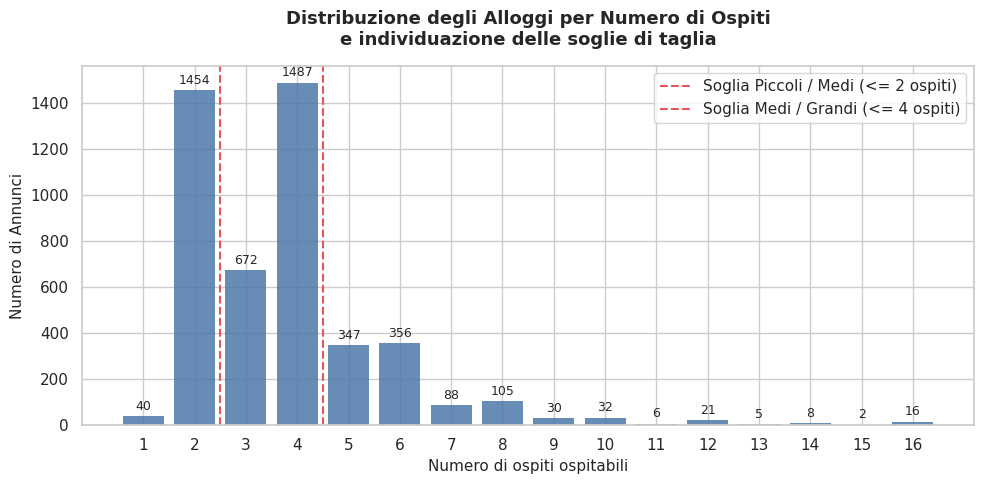

In [ ]:
# 1. Controlli testuali preliminari
print("=== VALORI MANCANTI ===")
print(listings_catania[["accommodates", "bedrooms", "beds"]].isna().sum())

print("\n=== CORRELAZIONE RANGHI (SPEARMAN) ===")
print(listings_catania[["accommodates", "bedrooms", "beds"]].corr(method="spearman"))

# 2. Visualizzazione Grafica della distribuzione di 'accommodates'
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 5))

# Calcoliamo le frequenze dei singoli valori di ospitalità
counts = listings_catania["accommodates"].value_counts().sort_index()

# Disegniamo il grafico a barre usando i colori coerenti del brand
bars = plt.bar(counts.index, counts.values, color=COLOR_BLUE, edgecolor="none", alpha=0.85)

# Aggiungiamo i valori numerici sopra ogni barra per massima chiarezza
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 15, f"{int(yval)}", ha="center", va="bottom", fontsize=9)

# Linee verticali per evidenziare le soglie di separazione proposte (0-2: piccoli, 3-4: medi, 5+: grandi)
plt.axvline(x=2.5, color=COLOR_RED, linestyle="--", linewidth=1.5, label="Soglia Piccoli / Medi (<= 2 ospiti)")
plt.axvline(x=4.5, color=COLOR_RED, linestyle="--", linewidth=1.5, label="Soglia Medi / Grandi (<= 4 ospiti)")

plt.title("Distribuzione degli Alloggi per Numero di Ospiti\ne individuazione delle soglie di taglia", fontsize=13, fontweight="bold", pad=15)
plt.xlabel("Numero di ospiti ospitabili", fontsize=11)
plt.ylabel("Numero di Annunci", fontsize=11)
plt.xticks(range(1, int(listings_catania["accommodates"].max()) + 1))
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

**1.4.2 Segnala e rimuovi i valori non validi**

In [ ]:
# Invalid = missing or less than 1 guest
invalid = listings_catania["accommodates"].isna() | (listings_catania["accommodates"] < 1)
print(f"Rows with invalid accommodates: {invalid.sum()}")

# Drop invalid rows (the count above documents what was removed)
listings_catania = listings_catania[~invalid].copy()

Rows with invalid accommodates: 0


**1.4.3 Crea la classe di taglia da `accommodates`**

In [ ]:
bins = [0, 2, 4, np.inf]  # (0,2], (2,4], (4,inf)
labels = ["small", "medium", "large"]

listings_catania["size_class"] = pd.cut(
    listings_catania["accommodates"], bins=bins, labels=labels
)

# Share of listings in each class
print(listings_catania["size_class"].value_counts(normalize=True).round(3))

size_class
medium    0.462
small     0.320
large     0.218
Name: proportion, dtype: float64


**1.4.4 Verifica di coerenza con le camere da letto**

In [ ]:
print(pd.crosstab(listings_catania["size_class"], listings_catania["bedrooms"], dropna=False))

bedrooms    0.0   1.0  2.0  3.0  4.0  5.0  6.0  7.0  8.0  9.0
size_class                                                   
small        32  1412   25   14    8    2    1    0    0    0
medium       19  1672  449   11    4    3    1    0    0    0
large         9   155  472  260   84   22    8    2    3    1


## 2. Casi sospetti e classi di dimensione

**2.1 Flag:** marchiamo come sospetti gli alloggi la cui classe di dimensione è incoerente con il numero di camere, senza eliminare nessuna riga. Aggiungiamo `suspicious_flag` (True/False) e `suspicious_type` (quale dei due casi).

In [ ]:
large_few_bedrooms = (listings_catania["size_class"] == "large") & (listings_catania["bedrooms"] <= 1)
small_many_bedrooms = (listings_catania["size_class"] == "small") & (listings_catania["bedrooms"] >= 3)

listings_catania["suspicious_flag"] = large_few_bedrooms | small_many_bedrooms
listings_catania["suspicious_type"] = np.select(
    [large_few_bedrooms, small_many_bedrooms],
    ["large_few_bedrooms", "small_many_bedrooms"],
    default="ok",
)

print(listings_catania["suspicious_flag"].value_counts())
print(f"Share of suspicious listings: {listings_catania['suspicious_flag'].mean():.1%}")
print(listings_catania["suspicious_type"].value_counts())
print("Missing bedrooms (not checkable):", listings_catania["bedrooms"].isna().sum())


suspicious_flag
False    4480
True      189
Name: count, dtype: int64
Share of suspicious listings: 4.0%
suspicious_type
ok                     4480
large_few_bedrooms      164
small_many_bedrooms      25
Name: count, dtype: int64
Missing bedrooms (not checkable): 0


**2.2 Analisi dei pattern:** per `room_type`, `accommodates`, `bedrooms` e `beds` calcoliamo quanti annunci ci sono e quale quota è sospetta, per capire se i sospetti sono più frequenti in certe categorie (es. case piccole o grandi).


--- room_type ---
                 n_listings  n_suspicious  share_suspicious
room_type                                                  
Entire home/apt        3388           145             0.043
Hotel room                3             0             0.000
Private room           1274            42             0.033
Shared room               4             2             0.500

--- accommodates ---
              n_listings  n_suspicious  share_suspicious
accommodates                                            
1                     40             0             0.000
2                   1454            25             0.017
3                    672             0             0.000
4                   1487             0             0.000
5                    347           121             0.349
6                    356            31             0.087
7                     88             5             0.057
8                    105             2             0.019
9                     30     

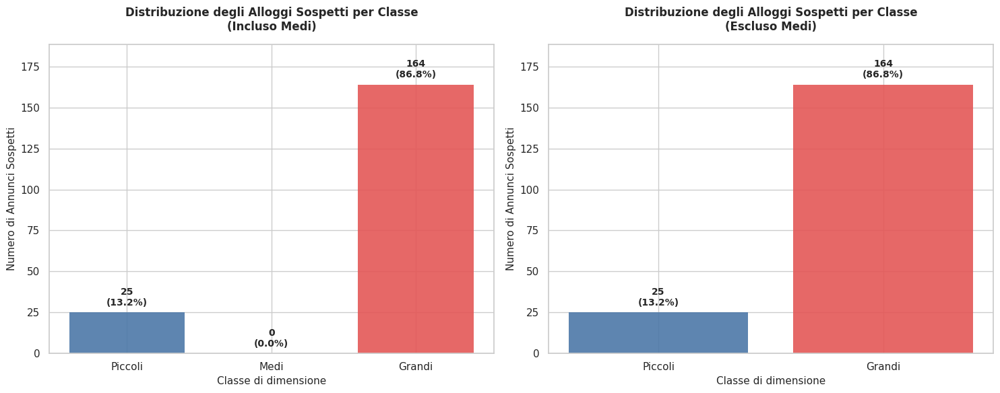

In [ ]:
for col in ["room_type", "accommodates", "bedrooms", "beds"]:
    summary = (
        listings_catania.groupby(col, observed=True)["suspicious_flag"]
        .agg(n_listings="size", n_suspicious="sum", share_suspicious="mean")
        .round(3)
    )
    print(f"\n--- {col} ---")
    print(summary)

# --- Visualizzazione Grafica dei Casi Sospetti per Classe ---
suspicious_data = listings_catania[listings_catania["suspicious_flag"] == True]
counts = suspicious_data["size_class"].value_counts().reindex(["small", "medium", "large"])

# Creiamo una figura con due subplot affiancati
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
sns.set_theme(style="whitegrid")

# --- GRAFICO 1: Originale con tutte le classi ---
colors_1 = [{"small": COLOR_BLUE, "medium": COLOR_YELLOW, "large": COLOR_RED}[c] for c in ["small", "medium", "large"]]
bars_1 = ax1.bar([IT_CLASS[c] for c in counts.index], counts.values, color=colors_1, edgecolor="none", alpha=0.9)

total_suspicious = counts.sum()
for bar in bars_1:
    height = bar.get_height()
    percentage = (height / total_suspicious * 100) if total_suspicious > 0 else 0
    ax1.text(
        bar.get_x() + bar.get_width() / 2.0,
        height + 3,
        f"{int(height)}\n({percentage:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

ax1.set_title("Distribuzione degli Alloggi Sospetti per Classe\n(Incluso Medi)", fontsize=12, fontweight="bold", pad=15)
ax1.set_xlabel("Classe di dimensione", fontsize=11)
ax1.set_ylabel("Numero di Annunci Sospetti", fontsize=11)
ax1.set_ylim(0, max(counts.values) * 1.15 if total_suspicious > 0 else 10)

# --- GRAFICO 2: Copia senza i 'Medi' (valore 0 rimosso) ---
# Filtriamo l'indice e i valori per escludere 'medium'
counts_no_medium = counts.drop("medium")
colors_2 = [{"small": COLOR_BLUE, "medium": COLOR_YELLOW, "large": COLOR_RED}[c] for c in counts_no_medium.index]

bars_2 = ax2.bar([IT_CLASS[c] for c in counts_no_medium.index], counts_no_medium.values, color=colors_2, edgecolor="none", alpha=0.9)

for bar in bars_2:
    height = bar.get_height()
    percentage = (height / total_suspicious * 100) if total_suspicious > 0 else 0
    ax2.text(
        bar.get_x() + bar.get_width() / 2.0,
        height + 3,
        f"{int(height)}\n({percentage:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

ax2.set_title("Distribuzione degli Alloggi Sospetti per Classe\n(Escluso Medi)", fontsize=12, fontweight="bold", pad=15)
ax2.set_xlabel("Classe di dimensione", fontsize=11)
ax2.set_ylabel("Numero di Annunci Sospetti", fontsize=11)
ax2.set_ylim(0, max(counts.values) * 1.15 if total_suspicious > 0 else 10)

plt.tight_layout()
plt.show()

**2.3 Confronto a tre scenari:** ripetiamo le analisi su tutti i dati, escludendo i sospetti e solo sui sospetti, per vedere se e di quanto cambiano distribuzione delle classi, tipologie di alloggio e prezzi.

In [ ]:
scenarios = {
    "1_all": listings_catania,
    "2_without_suspicious": listings_catania[~listings_catania["suspicious_flag"]],
    "3_only_suspicious": listings_catania[listings_catania["suspicious_flag"]],
}

# Size class distribution (share of listings)
size_dist = pd.DataFrame({
    name: d["size_class"].value_counts(normalize=True).reindex(["small", "medium", "large"])
    for name, d in scenarios.items()
}).round(3)
print("Size class distribution:\n", size_dist)

# Room type distribution (share of listings)
room_dist = pd.DataFrame({
    name: d["room_type"].value_counts(normalize=True)
    for name, d in scenarios.items()
}).round(3)
print("\nRoom type distribution:\n", room_dist)

# Overall price summary
price_summary = pd.DataFrame({
    name: {"n_listings": len(d), "mean_price": d["price"].mean(), "median_price": d["price"].median()}
    for name, d in scenarios.items()
}).round(2)
print("\nPrice summary:\n", price_summary)

# Change in mean and median price when suspicious listings are removed
change = (price_summary["2_without_suspicious"] / price_summary["1_all"] - 1).loc[["mean_price", "median_price"]]
print("\nChange scenario 2 vs 1 (%):\n", (change * 100).round(2))

Size class distribution:
             1_all  2_without_suspicious  3_only_suspicious
size_class                                                
small       0.320                 0.328              0.132
medium      0.462                 0.482              0.000
large       0.218                 0.190              0.868

Room type distribution:
                  1_all  2_without_suspicious  3_only_suspicious
room_type                                                      
Entire home/apt  0.726                 0.724              0.767
Hotel room       0.001                 0.001                NaN
Private room     0.273                 0.275              0.222
Shared room      0.001                 0.000              0.011

Price summary:
                 1_all  2_without_suspicious  3_only_suspicious
n_listings    4669.00               4480.00             189.00
mean_price     118.11                118.48             109.24
median_price    95.00                 95.00              95.00


**2.4 Definizione dei colori per le classi dimensionali:** impostiamo i colori da utilizzare per le visualizzazioni grafiche in base alla classe dimensionale della struttura (`size_class`). Assegniamo un colore specifico a ciascuna categoria (*small* = blu, *medium* = giallo, *large* = rosso) per garantire coerenza cromatica nei grafici successivi.

In [ ]:
df = listings_catania
labels = list(df["size_class"].cat.categories)   # ['small', 'medium', 'large']
colors = {"small": COLOR_BLUE, "medium": COLOR_YELLOW, "large": COLOR_RED}
color_list = [colors[l] for l in labels]

**2.5 Controllo sulle classi di dimensione:** quattro grafici per verificare che la divisione in piccoli, medi e grandi alloggi sia sensata: numero di alloggi per classe, distribuzione di `accommodates`, distribuzione di `bedrooms` dentro ogni classe e boxplot di `beds`.

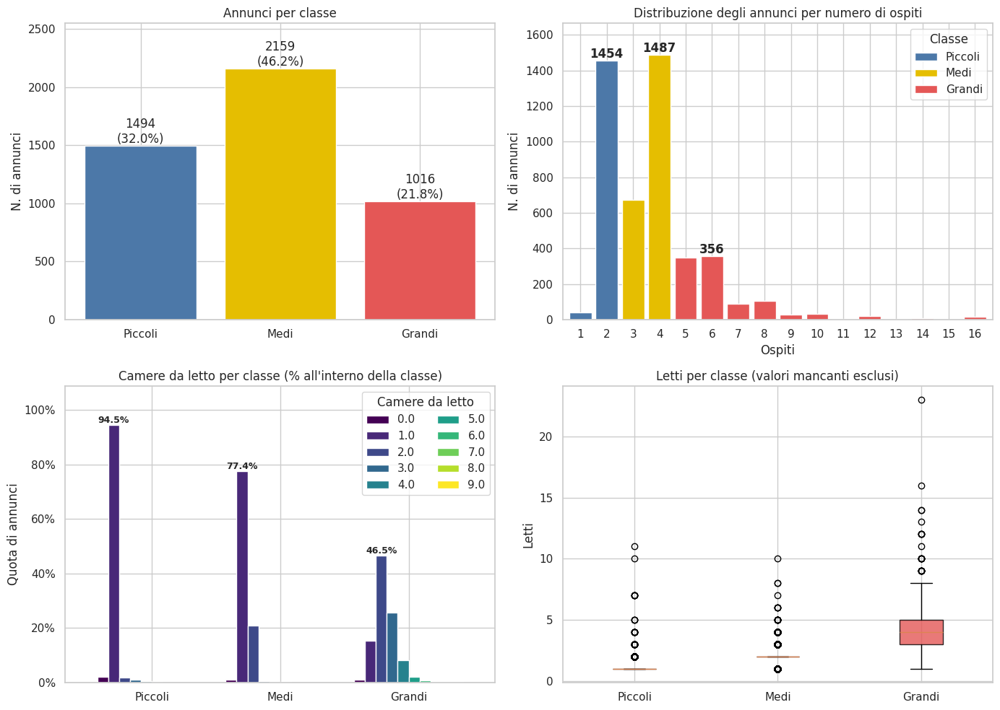

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Number of listings per class
ax = axes[0, 0]
counts = df["size_class"].value_counts().reindex(labels)
bars = ax.bar([IT_CLASS[l] for l in labels], counts.values, color=color_list)
for bar, n in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
            f"{n}\n({n / counts.sum():.1%})", ha="center", va="bottom")
ax.set_title("Annunci per classe")
ax.set_ylabel("N. di annunci")
ax.set_ylim(0, counts.max() * 1.18)

# 2. Distribution of accommodates, colored by class
ax = axes[0, 1]
acc = (df.groupby(["accommodates", "size_class"], observed=False)
         .size().unstack(fill_value=0)[labels])
acc.plot(kind="bar", stacked=True, ax=ax, color=color_list, width=0.85, rot=0)

# Aggiunta dei valori numerici sopra le colonne più alte di ogni categoria (small, medium, large)
# Calcoliamo i totali per ogni valore di 'accommodates' (altezza complessiva delle barre impilate)
total_by_acc = acc.sum(axis=1)
# Per ciascuna classe, troviamo quale 'accommodates' ha il valore massimo
for col in labels:
    max_acc_val = acc[col].idxmax()
    total_height = total_by_acc.loc[max_acc_val]
    # Trova l'indice della coordinata X corrispondente nella barra
    x_pos = acc.index.get_loc(max_acc_val)
    ax.text(x_pos, total_height, f"{int(total_height)}", ha="center", va="bottom", fontweight="bold")

ax.set_title("Distribuzione degli annunci per numero di ospiti")
ax.set_xlabel("Ospiti")
ax.set_ylabel("N. di annunci")
ax.set_ylim(0, total_by_acc.max() * 1.12)
ax.legend([IT_CLASS[l] for l in labels], title="Classe")

# 3. Distribution of bedrooms within each class (% per class)
ax = axes[1, 0]
bed = pd.crosstab(df["size_class"], df["bedrooms"], normalize="index").reindex(labels)
bed.plot(kind="bar", ax=ax, width=0.85, colormap="viridis", rot=0)
ax.set_xticklabels([IT_CLASS[l] for l in labels])

# Per ciascuna classe (small, medium, large sulle X), cerchiamo il valore massimo di quota e inseriamo il testo
num_classes = len(labels)
num_subbars = len(bed.columns)
width = 0.85

for i, class_label in enumerate(labels):
    # Trova il numero massimo di camere da letto (colonna) più frequente per questa classe
    max_bedroom_col = bed.loc[class_label].idxmax()
    max_val = bed.loc[class_label, max_bedroom_col]

    # Calcola la posizione X della specifica sotto-barra (all'interno del gruppo della categoria X)
    # Nei grafici a barre raggruppati di pandas, le sotto-barre sono centrate intorno all'indice intero i
    subbar_index = bed.columns.get_loc(max_bedroom_col)
    offset = (subbar_index - (num_subbars - 1) / 2) * (width / num_subbars)
    x_pos = i + offset

    ax.text(x_pos, max_val, f"{max_val:.1%}", ha="center", va="bottom", fontsize=9, fontweight="bold")

ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title("Camere da letto per classe (% all'interno della classe)")
ax.set_xlabel("")
ax.set_ylabel("Quota di annunci")
ax.set_ylim(0, bed.values.max() * 1.15)
ax.legend(title="Camere da letto", ncol=2)

# 4. Boxplot of beds per class (NaN excluded)
ax = axes[1, 1]
data = [df.loc[df["size_class"] == l, "beds"].dropna() for l in labels]
bp = ax.boxplot(data, patch_artist=True)
ax.set_xticklabels([IT_CLASS[l] for l in labels])
for patch, l in zip(bp["boxes"], labels):
    patch.set_facecolor({"small": COLOR_BLUE, "medium": COLOR_YELLOW, "large": COLOR_RED}[l])
    patch.set_alpha(0.8)
ax.set_title("Letti per classe (valori mancanti esclusi)")
ax.set_ylabel("Letti")

plt.tight_layout()
plt.show()

**Interpretazione:** le tre classi sono coerenti con ospiti, camere e letti: i piccoli hanno quasi sempre una sola camera (oltre il 90%), i grandi per lo più 2-3 camere e più letti. Per numerosità prevalgono i medi (2159), poi i piccoli (1494) e i grandi (1016).

**2.6 Distribuzione degli alloggi per classe (Catania):** grafico a torta con la quota di alloggi piccoli, medi e grandi. Le fette sotto il 5% sono staccate dal centro e senza percentuale sulla fetta; la legenda riporta conteggi e percentuali di tutte le classi.

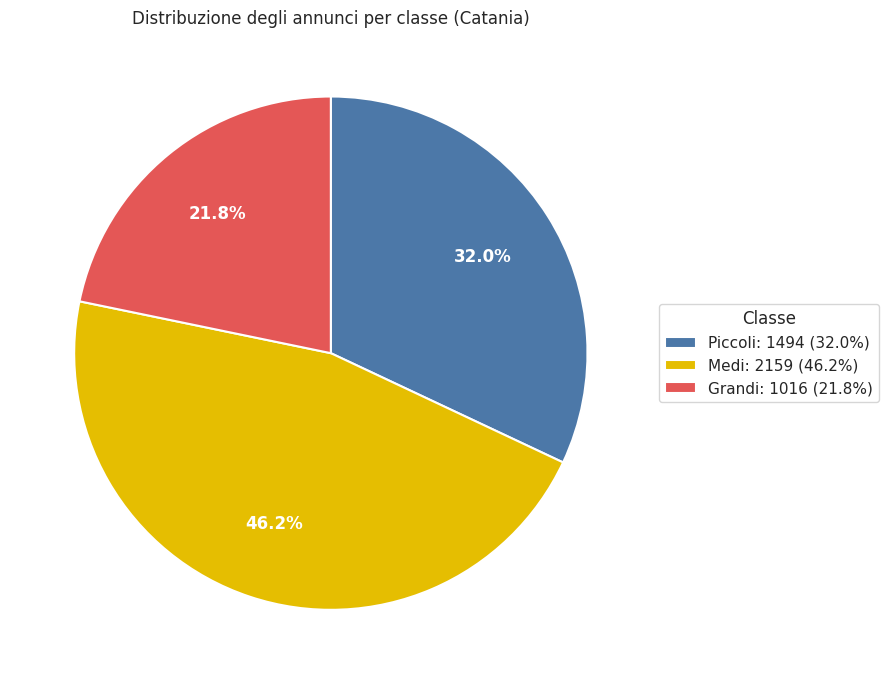

In [ ]:
counts = listings_catania["size_class"].value_counts().reindex(labels)
total = counts.sum()

# Visually separate the slices below 5%
explode = [0.08 if n / total < 0.05 else 0 for n in counts.values]

fig, ax = plt.subplots(figsize=(9, 7))
wedges, _, autotexts = ax.pie(
    counts.values,
    colors=color_list,
    explode=explode,
    startangle=90,
    counterclock=False,
    autopct=lambda p: f"{p:.1f}%" if p >= 5 else "",  # no text on tiny slices
    pctdistance=0.7,
    wedgeprops={"edgecolor": "white", "linewidth": 1.5},
)
for t in autotexts:
    t.set_color("white")
    t.set_fontweight("bold")

# Legend with counts and percentages: the smallest class is included here too
ax.legend(
    wedges,
    [f"{IT_CLASS[l]}: {n} ({n / total:.1%})" for l, n in zip(labels, counts.values)],
    title="Classe",
    loc="center left",
    bbox_to_anchor=(1, 0.5),
)
ax.set_title("Distribuzione degli annunci per classe (Catania)")
plt.tight_layout()
plt.show()

**Interpretazione:** i medi (3-4 ospiti) sono la quota più ampia, il 46,2% degli annunci; seguono i piccoli (32,0%) e i grandi (21,8%). Il mercato è quindi centrato su alloggi per piccoli gruppi, e solo un annuncio su cinque è grande.

## 3. Analisi dei prezzi per classe di dimensione

**3.1 Suddivisione del dataset:** creiamo tre sottoinsiemi (alloggi piccoli, medi e grandi) a partire da `size_class` e controlliamo quante righe contiene ciascuno, per verificare che la somma coincida con il totale degli annunci.

In [ ]:
# Split the dataset by size class (.copy() avoids warnings if we add columns later)
small_accommodation = listings_catania[listings_catania["size_class"] == "small"].copy()
medium_accommodation = listings_catania[listings_catania["size_class"] == "medium"].copy()
large_accommodation = listings_catania[listings_catania["size_class"] == "large"].copy()

# Check the number of rows in each subset
subsets = {
    "small_accommodation": small_accommodation,
    "medium_accommodation": medium_accommodation,
    "large_accommodation": large_accommodation,
}
for name, subset in subsets.items():
    print(f"{name}: {len(subset)} rows")

# The three subsets must add up to the full dataset
print(f"Total: {sum(len(s) for s in subsets.values())} (dataset: {len(listings_catania)})")

small_accommodation: 1494 rows
medium_accommodation: 2159 rows
large_accommodation: 1016 rows
Total: 4669 (dataset: 4669)


## 4. Analisi prezzi vs classi dimensionali

**4.1 Prezzo medio per classe:** calcoliamo media, mediana e numero di annunci per ciascuna classe (small, medium, large) per verificare se, mediamente, gli alloggi più grandi sono anche i più costosi. La mediana serve da controllo, perché è meno sensibile agli outlier.

In [ ]:
price_by_class = (
    listings_catania.groupby("size_class", observed=True)["price"]
    .agg(n_listings="count", mean_price="mean", median_price="median")
    .round(2)
)
print(price_by_class)

# Do prices increase with size, both for the mean and the median?
print("Mean increases with size:  ", price_by_class["mean_price"].is_monotonic_increasing)
print("Median increases with size:", price_by_class["median_price"].is_monotonic_increasing)

            n_listings  mean_price  median_price
size_class                                      
small             1386       97.21         82.50
medium            1960      109.30         93.28
large              938      167.39        136.00
Mean increases with size:   True
Median increases with size: True


**4.2 Grafico:** barre del prezzo medio per classe, con la mediana a fianco per confronto. Entrambe in tonalità oro, il colore dei prezzi.

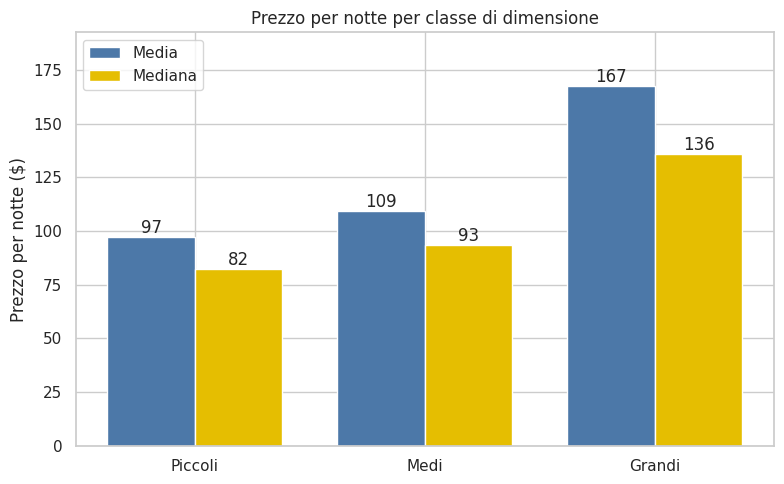

In [ ]:
color_mean = COLOR_BLUE   # blu = media
color_median = COLOR_YELLOW   # giallo = mediana (confronto principale)

fig, ax = plt.subplots(figsize=(8, 5))

x = np.arange(len(price_by_class))
width = 0.38
bars_mean = ax.bar(x - width / 2, price_by_class["mean_price"], width,
                   color=color_mean, label="Media")
bars_median = ax.bar(x + width / 2, price_by_class["median_price"], width,
                     color=color_median, label="Mediana")

for bar in list(bars_mean) + list(bars_median):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
            f"{bar.get_height():.0f}", ha="center", va="bottom")

ax.set_xticks(x)
ax.set_xticklabels([IT_CLASS[c] for c in price_by_class.index])
ax.set_title("Prezzo per notte per classe di dimensione")
ax.set_ylabel("Prezzo per notte ($)")
ax.set_ylim(0, price_by_class["mean_price"].max() * 1.15)
ax.legend()
plt.tight_layout()
plt.show()

**Interpretazione:** il prezzo sale con la dimensione: la mediana passa da 82 USD (piccoli) a 93 (medi) a 136 (grandi). La media è sempre sopra la mediana, segno di una coda di annunci cari che la spinge in alto.

**4.3 Controllo sugli outlier:** ripetiamo il calcolo escludendo i prezzi sopra il 99° percentile, per vedere se pochi annunci molto costosi spostano le medie.

In [ ]:
cap = listings_catania["price"].quantile(0.99)
print(f"99th percentile: {cap:.2f}")

price_by_class_capped = (
    listings_catania[listings_catania["price"] <= cap]
    .groupby("size_class", observed=True)["price"]
    .agg(n_listings="count", mean_price="mean", median_price="median")
    .round(2)
)
print(price_by_class_capped)

99th percentile: 494.64
            n_listings  mean_price  median_price
size_class                                      
small             1383       92.08         82.45
medium            1945      103.66         93.00
large              913      152.40        134.00


## 5. Analisi Geospaziale: Distanza dal Centro e Impatto sul Prezzo

**5.1 Classificazione della posizione ("In centro" vs "Fuori centro"):** assegniamo a ogni struttura un'etichetta in base alla distanza dal centro (stimato in Piazza Duomo, con raggio di 1.5 km), per poi verificare quante strutture ricadono in ciascuna area.

Distribution of listings by location:
location
Center            3667
Outside Center    1002
Name: count, dtype: int64


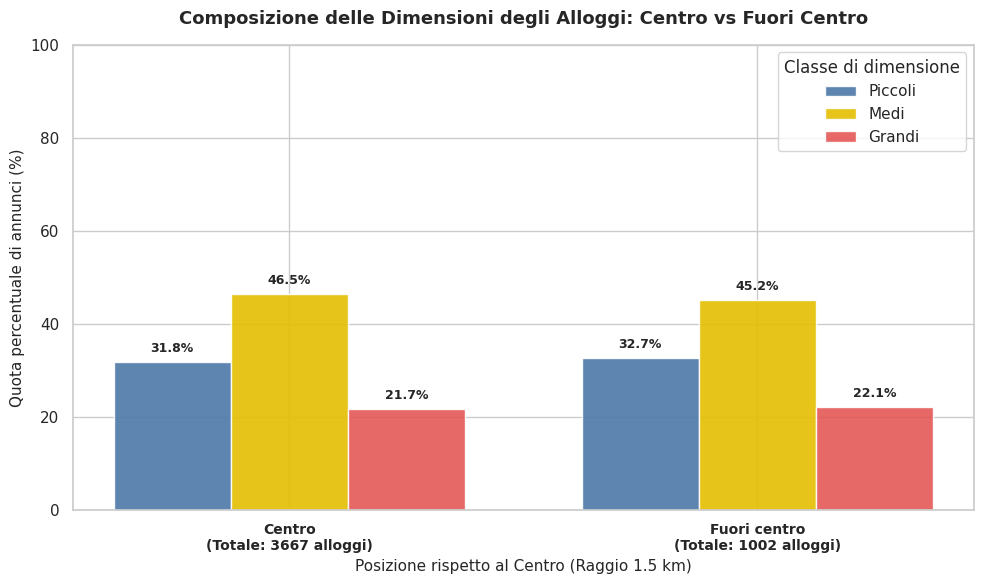

In [ ]:
# Calcolo della distanza dal centro per ogni alloggio
listings_catania["dist_center_km"] = haversine_km(
    CENTER_LAT, CENTER_LON,
    listings_catania["latitude"], listings_catania["longitude"]
)

# Assegnazione etichetta: in centro o fuori centro
listings_catania["location"] = np.where(
    listings_catania["dist_center_km"] <= RADIUS_KM,
    "Center",
    "Outside Center"
)

print("Distribution of listings by location:")
print(listings_catania["location"].value_counts())

# --- Visualizzazione Grafica: Differenza tra Centro e Fuori Centro ---
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Conteggio totale dei listing per ciascun gruppo per l'etichetta dell'asse X
totals_by_location = listings_catania["location"].value_counts()
x_labels = [
    f"{IT_LOC[loc]}\n(Totale: {totals_by_location[loc]} alloggi)"
    for loc in ["Center", "Outside Center"]
]

# Creazione della tabella di contingenza normalizzata per percentuale per colonna (posizione)
location_size_pct = pd.crosstab(
    listings_catania["size_class"],
    listings_catania["location"],
    normalize="columns"
) * 100

# Riordiniamo le colonne per assicurarci la corrispondenza con l'ordine delle etichette
location_size_pct = location_size_pct[["Center", "Outside Center"]]

x = np.arange(len(location_size_pct.columns))
width = 0.25
classes = ["small", "medium", "large"]

# Disegno delle barre per ciascuna classe di dimensione usando i colori delle classi dimensionali
for i, cls in enumerate(classes):
    bar_heights = location_size_pct.loc[cls]
    bars = plt.bar(
        x + (i - 1) * width,
        bar_heights,
        width,
        label=IT_CLASS[cls],
        color={"small": COLOR_BLUE, "medium": COLOR_YELLOW, "large": COLOR_RED}[cls],
        alpha=0.9
    )
    # Aggiunta delle etichette con le percentuali sopra le barre
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2.0,
            height + 1.5,
            f"{height:.1f}%",
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold"
        )

plt.title("Composizione delle Dimensioni degli Alloggi: Centro vs Fuori Centro", fontsize=13, fontweight="bold", pad=15)
plt.xlabel("Posizione rispetto al Centro (Raggio 1.5 km)", fontsize=11)
plt.ylabel("Quota percentuale di annunci (%)", fontsize=11)
plt.xticks(x, x_labels, fontsize=10, fontweight="bold")
plt.ylim(0, max(location_size_pct.values.max() * 1.15, 100))
plt.legend(title="Classe di dimensione", loc="upper right")
plt.tight_layout()
plt.show()

**5.2 Correlazione posizione/prezzo a parità di classe dimensionale:** raggruppiamo i dati incrociando la `size_class` (piccola, media, grande) con la `posizione` per calcolare il prezzo medio e mediano. Questo ci permette di verificare se le strutture centrali costano effettivamente di più a parità di capienza.

--- Price Analysis: Size Class and Location ---
                           n_listings  mean_price  median_price
size_class location                                            
small      Center                1081       96.96         83.28
           Outside Center         305       98.09         79.50
medium     Center                1548      111.07         94.00
           Outside Center         412      102.66         91.66
large      Center                 740      167.51        137.76
           Outside Center         198      166.92        127.50


<Figure size 1200x600 with 0 Axes>

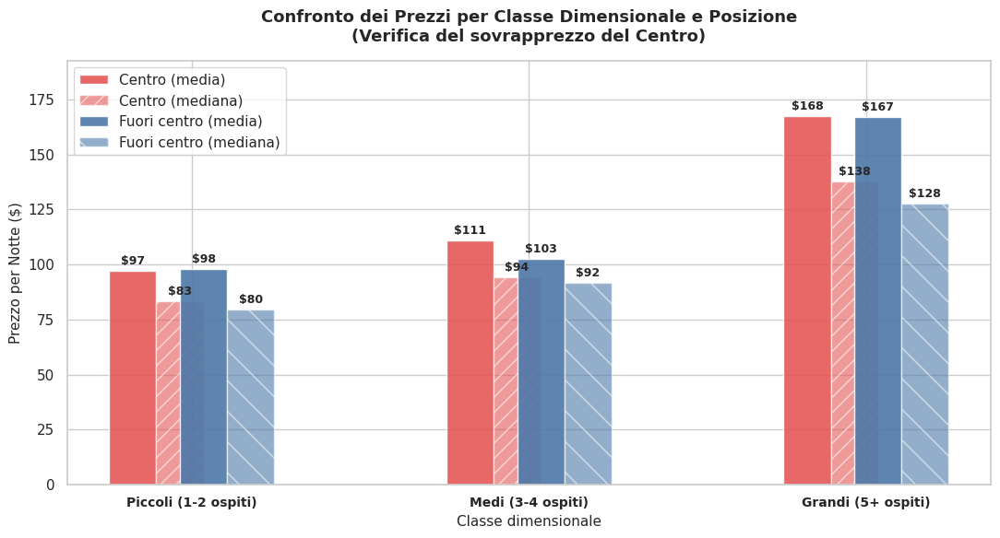

In [ ]:
# Calcolo metriche di prezzo per classe e posizione
price_by_location_class = (
    listings_catania.groupby(["size_class", "location"], observed=True)["price"]
    .agg(
        n_listings="count",
        mean_price="mean",
        median_price="median"
    )
    .round(2)
)

print("--- Price Analysis: Size Class and Location ---")
print(price_by_location_class)

# --- Visualizzazione Grafica della Relazione Posizione/Prezzo per Classe ---
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

# Reshape dei dati per facilitare il plotting
plot_data = price_by_location_class.reset_index()

x = np.arange(len(plot_data["size_class"].unique()))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

# Estraiamo i dati per Centro e Fuori Centro
center_data = plot_data[plot_data["location"] == "Center"]
outside_data = plot_data[plot_data["location"] == "Outside Center"]

# Colori coerenti con il brand (utilizziamo sfumature dei colori dei prezzi)
color_center = COLOR_RED
color_outside = COLOR_BLUE

# Disegno delle barre per la Media e la Mediana
bars_center_mean = ax.bar(x - width/2, center_data["mean_price"], width*0.4,
                          label="Centro (media)", color=color_center, alpha=0.9)
bars_center_med = ax.bar(x - width/2 + width*0.4, center_data["median_price"], width*0.4,
                         label="Centro (mediana)", color=color_center, alpha=0.6, hatch='//')

bars_outside_mean = ax.bar(x + width/2 - width*0.4, outside_data["mean_price"], width*0.4,
                           label="Fuori centro (media)", color=color_outside, alpha=0.9)
bars_outside_med = ax.bar(x + width/2, outside_data["median_price"], width*0.4,
                          label="Fuori centro (mediana)", color=color_outside, alpha=0.6, hatch='\\')

# Funzione per aggiungere le etichette di testo sopra le barre
def autolabel(bars):
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'${height:.0f}',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9, fontweight='bold')

autolabel(bars_center_mean)
autolabel(bars_center_med)
autolabel(bars_outside_mean)
autolabel(bars_outside_med)

# Configurazione degli assi e legenda
ax.set_title("Confronto dei Prezzi per Classe Dimensionale e Posizione\n(Verifica del sovrapprezzo del Centro)", fontsize=13, fontweight="bold", pad=15)
ax.set_xlabel("Classe dimensionale", fontsize=11)
ax.set_ylabel("Prezzo per Notte ($)", fontsize=11)
ax.set_xticks(x)
ax.set_xticklabels([IT_CLASS_GUESTS[c] for c in ["small", "medium", "large"]], fontsize=10, fontweight="bold")
ax.set_ylim(0, plot_data["mean_price"].max() * 1.15)
ax.legend(loc="upper left", frameon=True)

plt.tight_layout()
plt.show()

**5.3 Confronto diretto e sovrapprezzo del centro:** creiamo una tabella riassuntiva (pivot) per confrontare immediatamente i prezzi medi e calcoliamo la variazione percentuale (sovrapprezzo) richiesta dagli alloggi in centro rispetto a quelli periferici.

In [ ]:
# Tabella pivot per il confronto diretto dei prezzi medi
mean_price_pivot = price_by_location_class["mean_price"].unstack()
print("--- Direct Comparison Mean Price ($) ---")
print(mean_price_pivot)

# Calcolo della variazione percentuale del prezzo medio
price_premium_perc = ((mean_price_pivot["Center"] / mean_price_pivot["Outside Center"]) - 1) * 100
print("\n--- Mean Price Premium 'Center' vs 'Outside Center' (%) ---")
print(price_premium_perc.round(2).astype(str) + " %")

--- Direct Comparison Mean Price ($) ---
location    Center  Outside Center
size_class                        
small        96.96           98.09
medium      111.07          102.66
large       167.51          166.92

--- Mean Price Premium 'Center' vs 'Outside Center' (%) ---
size_class
small     -1.15 %
medium     8.19 %
large      0.35 %
dtype: object


**5.4 Controllo di robustezza:** ripetiamo il confronto centro/fuori centro con le mediane, senza gli outlier di prezzo (oltre PRICE_CAP (494,64 USD)) e con raggi diversi, per vedere se la conclusione dipende dalla definizione di "centro".

In [ ]:
print(f"Outliers (price > {PRICE_CAP}):", listings_catania["price_outlier"].sum())

valid = listings_catania[listings_catania["price"].notna() & ~listings_catania["price_outlier"]]

# Sample size per cell at the radius used so far
print(valid.groupby(["size_class", "location"], observed=True).size().unstack())

# Distance distribution
print("\nDistance from center (km):")
print(listings_catania["dist_center_km"].quantile([0.25, 0.5, 0.75, 0.9]).round(2))

# Median premium of the center for different radii
shares, premiums = {}, {}
for r in [0.5, 1.0, 1.2, 1.5, 2.0]:
    in_center = valid["dist_center_km"] <= r
    med = valid.groupby(["size_class", in_center], observed=True)["price"].median().unstack()
    med.columns = ["Outside Center", "Center"]   # False, True
    premiums[f"{r} km"] = ((med["Center"] / med["Outside Center"] - 1) * 100).round(1)
    shares[f"{r} km"] = round(in_center.mean() * 100, 1)

print("\nShare of listings in the center (%):", shares)
print("\nMedian price premium of center vs outside (%):")
print(pd.DataFrame(premiums))

Outliers (price > 494.64): 43
location    Center  Outside Center
size_class                        
small         1080             303
medium        1533             412
large          722             191

Distance from center (km):
0.25    0.49
0.50    0.81
0.75    1.36
0.90    2.44
Name: dist_center_km, dtype: float64

Share of listings in the center (%): {'0.5 km': np.float64(25.6), '1.0 km': np.float64(61.2), '1.2 km': np.float64(70.4), '1.5 km': np.float64(78.6), '2.0 km': np.float64(86.1)}

Median price premium of center vs outside (%):
            0.5 km  1.0 km  1.2 km  1.5 km  2.0 km
size_class                                        
small         14.7     6.9     3.0     5.4    -0.9
medium        10.3     4.4     2.2     2.2     0.5
large         15.7     1.5     4.1     8.1     9.8


**5.5 Zone per distanza dal centro:** poiché il dataset non contiene quartieri di Catania, dividiamo gli annunci in fasce di distanza da Piazza Duomo e confrontiamo numero di annunci, densità, prezzo mediano e recensioni. È la risposta a "dove si concentra il turismo?" e a "il prezzo cambia da zona a zona?".

In [ ]:
edges = [0, 0.5, 1.0, 1.5, 2.5]
band_labels = ["0-0.5 km", "0.5-1 km", "1-1.5 km", "1.5-2.5 km", ">2.5 km"]
listings_catania["dist_band"] = pd.cut(
    listings_catania["dist_center_km"], bins=edges + [np.inf],
    labels=band_labels, include_lowest=True
)

g = listings_catania.groupby("dist_band", observed=True)
zone = g.size().rename("n_listings").to_frame()
zone["share_%"] = (zone["n_listings"] / zone["n_listings"].sum() * 100).round(1)

# Density (ring areas; the last band is open-ended)
area = [np.pi * (b ** 2 - a ** 2) for a, b in zip(edges[:-1], edges[1:])] + [np.nan]
zone["listings_per_km2"] = (zone["n_listings"] / np.array(area)).round(0)

# Median price (listings with a price, outliers excluded)
valid_price = listings_catania[listings_catania["price"].notna() & ~listings_catania["price_outlier"]]
zone["median_price"] = valid_price.groupby("dist_band", observed=True)["price"].median()

# Reviews as a proxy of activity
zone["share_no_reviews_%"] = (g["number_of_reviews"].apply(lambda s: (s == 0).mean()) * 100).round(1)
zone["median_reviews_pm"] = (listings_catania[listings_catania["number_of_reviews"] > 0]
                             .groupby("dist_band", observed=True)["reviews_per_month"].median().round(2))
zone["total_reviews"] = g["number_of_reviews"].sum()

print(zone)

            n_listings  share_%  listings_per_km2  median_price  \
dist_band                                                         
0-0.5 km          1186     25.4            1510.0       103.385   
0.5-1 km          1644     35.2             698.0        92.000   
1-1.5 km           837     17.9             213.0        91.625   
1.5-2.5 km         560     12.0              45.0        88.000   
>2.5 km            442      9.5               NaN        98.000   

            share_no_reviews_%  median_reviews_pm  total_reviews  
dist_band                                                         
0-0.5 km                  18.6               1.01          71608  
0.5-1 km                  23.4               0.86          72047  
1-1.5 km                  27.4               0.62          19624  
1.5-2.5 km                23.9               0.51          12999  
>2.5 km                   28.3               0.50           8874  


**5.6 Grafico:** quota di annunci e quota di recensioni per fascia di distanza dal centro. Le recensioni sono un proxy dell'attività turistica: se le barre marroni sono più alte di quelle acquamarina, la fascia attira più recensioni di quanto pesi in numero di annunci.

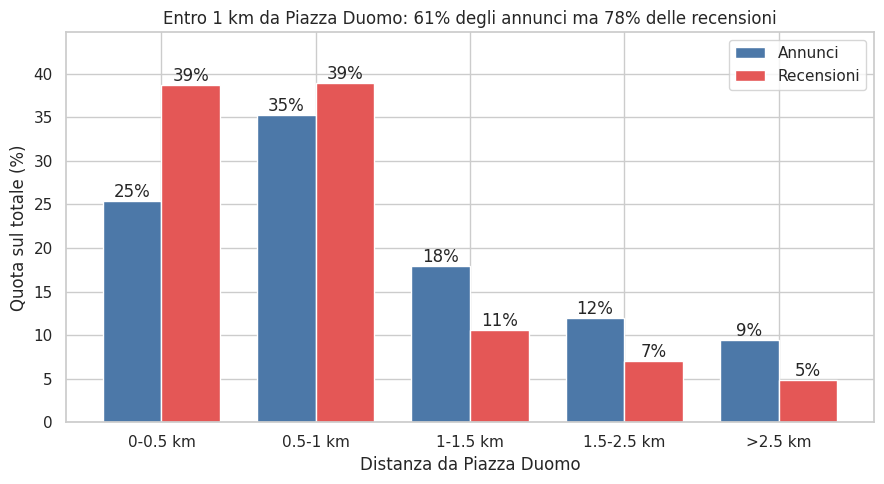

In [ ]:
share_listings = zone["n_listings"] / zone["n_listings"].sum() * 100
share_reviews = zone["total_reviews"] / zone["total_reviews"].sum() * 100

x = np.arange(len(zone))
width = 0.38

fig, ax = plt.subplots(figsize=(9, 5))
bars_l = ax.bar(x - width / 2, share_listings.values, width, color=COLOR_BLUE, label="Annunci")
bars_r = ax.bar(x + width / 2, share_reviews.values, width, color=COLOR_RED, label="Recensioni")

for bar in list(bars_l) + list(bars_r):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
            f"{bar.get_height():.0f}%", ha="center", va="bottom")

within_l = share_listings.iloc[:2].sum()
within_r = share_reviews.iloc[:2].sum()

ax.set_xticks(x)
ax.set_xticklabels(zone.index)
ax.set_xlabel("Distanza da Piazza Duomo")
ax.set_ylabel("Quota sul totale (%)")
ax.set_title(f"Entro 1 km da Piazza Duomo: {within_l:.0f}% degli annunci ma {within_r:.0f}% delle recensioni")
ax.set_ylim(0, max(share_listings.max(), share_reviews.max()) * 1.15)
ax.legend()
plt.tight_layout()
plt.show()

**Interpretazione:** il centro pesa più nelle recensioni che negli annunci: entro 500 m c'è il 25% degli annunci ma il 39% delle recensioni. Oltre 1 km i pesi si invertono e gli annunci superano le recensioni.

**5.7 Riepilogo del sovrapprezzo del centro:** mettiamo in un'unica tabella il sovrapprezzo percentuale del centro (raggio 1,5 km) rispetto al fuori centro, per classe di dimensione, calcolato con media e mediana, con tutti i prezzi e senza gli outlier oltre 500 USD. Serve a capire se la conclusione dipende dalla misura scelta.

In [ ]:
base = listings_catania[listings_catania["price"].notna()]
versions = {
    "all prices": base,
    f"without outliers (>{PRICE_CAP})": base[~base["price_outlier"]],
}

rows = {}
for vname, d in versions.items():
    for stat in ["mean", "median"]:
        t = d.groupby(["size_class", "location"], observed=True)["price"].agg(stat).unstack()
        rows[f"{stat} - {vname}"] = ((t["Center"] / t["Outside Center"] - 1) * 100).round(1)

premium = pd.DataFrame(rows).T
print("Center premium vs outside center (%), radius 1.5 km:")
print(premium)

# Sample size per cell (listings with a price, without outliers)
print("\nListings per cell:")
print(versions[f"without outliers (>{PRICE_CAP})"].groupby(["size_class", "location"], observed=True).size().unstack())

Center premium vs outside center (%), radius 1.5 km:
size_class                           small  medium  large
mean - all prices                     -1.2     8.2    0.4
median - all prices                    4.8     2.5    8.1
mean - without outliers (>494.64)     -1.2     1.2    3.2
median - without outliers (>494.64)    5.4     2.2    8.1

Listings per cell:
location    Center  Outside Center
size_class                        
small         1080             303
medium        1533             412
large          722             191


**Conclusione 5.7:** a parità di classe dimensionale il centro costa mediamente più del fuori centro, ma di poco. Il sovrapprezzo mediano a 1,5 km è circa +5% per i piccoli, +2% per i medi e +8% per i grandi, ed è stabile con o senza gli outlier. Con la media il risultato è meno netto (da −1% a +2% senza outlier) e il +8% dei medi sparisce senza gli outlier. Il premio più alto si concentra nel nucleo entro 500 metri da Piazza Duomo (+10-16% sulla mediana, vedi 5.4). Il confronto è descrittivo, senza test statistici, e riguarda solo gli annunci con prezzo.

## 6. Visualizzazione Grafica: Mappa Interattiva degli Alloggi

Per visualizzare la distribuzione spaziale delle strutture, creiamo una mappa interattiva utilizzando la libreria `folium`.

Invece di usare una heatmap continua (che perde definizione ingrandendo la mappa), utilizziamo una rappresentazione a punti (scatter map). Ogni punto sulla mappa rappresenta un alloggio e il suo colore indica la classe dimensionale (`small`, `medium`, `large`), permettendoci di vedere a colpo d'occhio se gli alloggi più grandi o più piccoli si concentrano in aree specifiche.

In [ ]:
m = folium.Map(location=[CENTER_LAT, CENTER_LON], zoom_start=13, tiles=None)
folium.TileLayer(
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}',
    attr='Esri', name='Esri Street Map'
).add_to(m)

# Boundary of the "Center" area
folium.Circle(
    [CENTER_LAT, CENTER_LON], radius=RADIUS_KM * 1000,
    color="black", weight=2, dash_array="6", fill=False,
    tooltip=f"Centro ({RADIUS_KM} km da Piazza Duomo)"
).add_to(m)

class_colors = {"small": COLOR_BLUE, "medium": COLOR_YELLOW, "large": COLOR_RED}
map_data = listings_catania.dropna(subset=["latitude", "longitude", "size_class"])

# One layer per class; the least numerous is drawn last (on top)
for cls in ["medium", "small", "large"]:
    layer = folium.FeatureGroup(name=IT_CLASS[cls])
    for row in map_data[map_data["size_class"] == cls].itertuples():
        price_txt = f"${row.price:.0f}" if pd.notna(row.price) else "n.d."
        folium.CircleMarker(
            location=[row.latitude, row.longitude],
            radius=2.5,
            color=class_colors[cls], fill=True, fill_color=class_colors[cls],
            fill_opacity=0.6, weight=0.5,
            popup=f"Classe: {IT_CLASS[cls]}<br>Prezzo: {price_txt}",
        ).add_to(layer)
    layer.add_to(m)

legend_html = f"""
<div style="position: fixed; bottom: 30px; left: auto; right: 30px; z-index: 9999; background: white;
            padding: 8px 12px; border: 1px solid #999; font-size: 13px;">
<b>Classe di dimensione</b><br>
<span style="color:{class_colors['small']};">&#9679;</span> piccoli (1-2 ospiti)<br>
<span style="color:{class_colors['medium']};">&#9679;</span> medi (3-4 ospiti)<br>
<span style="color:{class_colors['large']};">&#9679;</span> grandi (5+ ospiti)
</div>
"""
# Aggiungi un blocco CSS che desatura i tile della mappa
grayscale_css = """
<style>
.leaflet-tile-pane {
    filter: grayscale(100%);
    -webkit-filter: grayscale(100%);
}
</style>
"""
m.get_root().html.add_child(folium.Element(grayscale_css))
m.get_root().html.add_child(folium.Element(legend_html))
folium.LayerControl(collapsed=False).add_to(m)
m

**Interpretazione:** gli alloggi si addensano attorno a Piazza Duomo: il 61% degli annunci è entro 1 km e la densità scende da 1.510 annunci/km² nei primi 500 m a 45 tra 1,5 e 2,5 km. I colori mostrano la classe dimensionale di ciascun annuncio.

## 7. Performance

**7.1 Controllo preliminare:** verifichiamo che le colonne delle recensioni e della disponibilità siano presenti, quanti valori mancano e se `reviews_per_month` è vuota proprio per gli annunci senza recensioni. Le recensioni sono solo un proxy dell'occupazione: il dataset non dice quante notti sono state prenotate.

In [ ]:
perf_cols = ["reviews_per_month", "number_of_reviews", "availability_365", "first_review", "last_review"]

print("Missing columns:", [c for c in perf_cols if c not in listings_catania.columns])
print(listings_catania[[c for c in perf_cols if c in listings_catania.columns]].isna().sum())

# Listings with no reviews at all
print("Listings with 0 reviews:", (listings_catania["number_of_reviews"] == 0).sum())

# Is reviews_per_month empty exactly when there are no reviews?
print("NaN reviews_per_month <-> 0 reviews:",
      (listings_catania["reviews_per_month"].isna() == (listings_catania["number_of_reviews"] == 0)).mean().round(3))

print(listings_catania["reviews_per_month"].describe())

Missing columns: []
reviews_per_month    1093
number_of_reviews       0
availability_365        0
first_review         1093
last_review          1093
dtype: int64
Listings with 0 reviews: 1093
NaN reviews_per_month <-> 0 reviews: 1.0
count    3576.000000
mean        1.282097
std         1.463438
min         0.010000
25%         0.220000
50%         0.750000
75%         1.860000
max        10.040000
Name: reviews_per_month, dtype: float64


**7.2 Recensioni mensili per tipologia (`room_type`):** confrontiamo media e mediana di `reviews_per_month` in due versioni: includendo gli annunci senza recensioni (contati come 0) ed escludendoli. Così vediamo quanto la scelta cambia il risultato.

In [ ]:
# Version A: listings without reviews count as 0
perf_a = (
    listings_catania.assign(reviews_pm=listings_catania["reviews_per_month"].fillna(0))
    .groupby("room_type")["reviews_pm"]
    .agg(n_listings="count", mean_reviews="mean", median_reviews="median")
    .round(2)
)

# Version B: only listings with at least one review
perf_b = (
    listings_catania[listings_catania["number_of_reviews"] > 0]
    .groupby("room_type")["reviews_per_month"]
    .agg(n_listings="count", mean_reviews="mean", median_reviews="median")
    .round(2)
)

print("--- A: including listings with 0 reviews ---")
print(perf_a)
print("\n--- B: only listings with at least 1 review ---")
print(perf_b)

--- A: including listings with 0 reviews ---
                 n_listings  mean_reviews  median_reviews
room_type                                                
Entire home/apt        3388          1.10            0.57
Hotel room                3          0.25            0.00
Private room           1274          0.67            0.06
Shared room               4          0.40            0.30

--- B: only listings with at least 1 review ---
                 n_listings  mean_reviews  median_reviews
room_type                                                
Entire home/apt        2823          1.32            0.85
Hotel room                1          0.75            0.75
Private room            748          1.15            0.51
Shared room               4          0.40            0.30


**7.3 Grafico:** mediana delle recensioni mensili per `room_type`, nelle due versioni (tutti gli annunci con i senza recensioni contati come 0, e solo annunci con almeno una recensione). Escludiamo `Hotel room` e `Shared room` per numerosità troppo bassa (3 e 4 annunci).

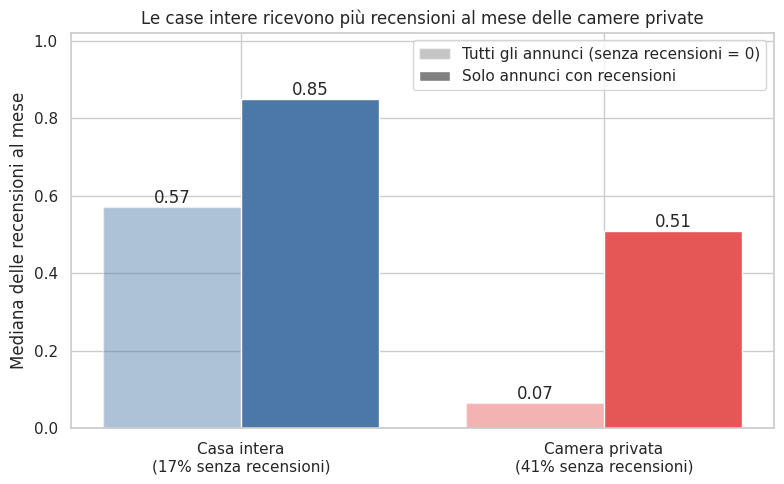

In [ ]:
rooms = ["Entire home/apt", "Private room"]
room_colors = {"Entire home/apt": COLOR_BLUE, "Private room": COLOR_RED, "Hotel room": COLOR_YELLOW, "Shared room": COLOR_YELLOW}   # blu = casa intera, rosso = camera privata

sub = listings_catania[listings_catania["room_type"].isin(rooms)]

median_all = (sub.assign(r=sub["reviews_per_month"].fillna(0))
                 .groupby("room_type")["r"].median().reindex(rooms))
median_rev = (sub[sub["number_of_reviews"] > 0]
                 .groupby("room_type")["reviews_per_month"].median().reindex(rooms))
share_zero = sub.groupby("room_type")["number_of_reviews"].apply(lambda s: (s == 0).mean()).reindex(rooms)

x = np.arange(len(rooms))
width = 0.38
bar_colors = [room_colors[r] for r in rooms]

fig, ax = plt.subplots(figsize=(8, 5))
bars_all = ax.bar(x - width / 2, median_all.values, width, color=bar_colors, alpha=0.45)
bars_rev = ax.bar(x + width / 2, median_rev.values, width, color=bar_colors)

for bar in list(bars_all) + list(bars_rev):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
            f"{bar.get_height():.2f}", ha="center", va="bottom")

ax.set_xticks(x)
ax.set_xticklabels([f"{IT_ROOM[r]}\n({share_zero[r]:.0%} senza recensioni)" for r in rooms])
ax.set_ylabel("Mediana delle recensioni al mese")
ax.set_title("Le case intere ricevono più recensioni al mese delle camere private")
ax.set_ylim(0, median_rev.max() * 1.2)
ax.legend(handles=[Patch(facecolor="gray", alpha=0.45, label="Tutti gli annunci (senza recensioni = 0)"),
                   Patch(facecolor="gray", label="Solo annunci con recensioni")])
plt.tight_layout()
plt.show()

**Interpretazione:** gli appartamenti interi ricevono più recensioni al mese delle stanze private: mediana 0,57 contro 0,07 con tutti gli annunci, 0,85 contro 0,51 solo con gli annunci recensiti. Il divario con tutti gli annunci dipende anche dal 41% di stanze private senza recensioni.

**7.4 Recensioni mensili per classe di dimensione (`size_class`):** confrontiamo media e mediana di `reviews_per_month` per alloggi piccoli, medi e grandi, in due versioni: includendo gli annunci senza recensioni (contati come 0) ed escludendoli. Aggiungiamo la quota di annunci senza recensioni per classe, perché può spiegare le differenze.

In [ ]:
# Version A: listings without reviews count as 0
perf_size_a = (
    listings_catania.assign(reviews_pm=listings_catania["reviews_per_month"].fillna(0))
    .groupby("size_class", observed=True)["reviews_pm"]
    .agg(n_listings="count", mean_reviews="mean", median_reviews="median")
    .round(2)
)

# Version B: only listings with at least one review
perf_size_b = (
    listings_catania[listings_catania["number_of_reviews"] > 0]
    .groupby("size_class", observed=True)["reviews_per_month"]
    .agg(n_listings="count", mean_reviews="mean", median_reviews="median")
    .round(2)
)

# Share of listings with no reviews, per class
perf_size_a["share_no_reviews"] = (
    listings_catania.groupby("size_class", observed=True)["number_of_reviews"]
    .apply(lambda s: (s == 0).mean())
    .round(3)
)

print("--- A: including listings with 0 reviews ---")
print(perf_size_a)
print("\n--- B: only listings with at least 1 review ---")
print(perf_size_b)

--- A: including listings with 0 reviews ---
            n_listings  mean_reviews  median_reviews  share_no_reviews
size_class                                                            
small             1494          0.98            0.26             0.299
medium            2159          1.00            0.43             0.222
large             1016          0.95            0.50             0.163

--- B: only listings with at least 1 review ---
            n_listings  mean_reviews  median_reviews
size_class                                          
small             1047          1.40            0.78
medium            1679          1.28            0.76
large              850          1.14            0.68


**7.5 Grafico:** mediana delle recensioni mensili per classe di dimensione, nelle due versioni, con la quota di annunci senza recensioni sotto ogni classe.

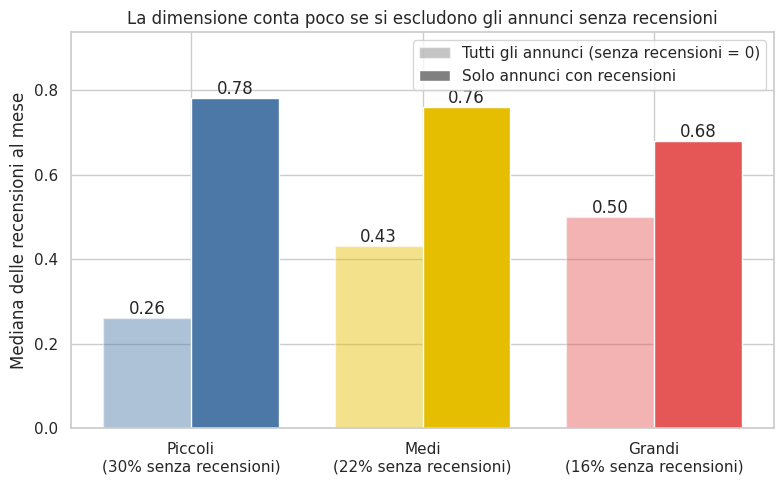

In [ ]:
size_colors = {"small": COLOR_BLUE, "medium": COLOR_YELLOW, "large": COLOR_RED}
classes = ["small", "medium", "large"]
bar_colors = [size_colors[c] for c in classes]

median_all = perf_size_a["median_reviews"].reindex(classes)
median_rev = perf_size_b["median_reviews"].reindex(classes)
share_zero = perf_size_a["share_no_reviews"].reindex(classes)

x = np.arange(len(classes))
width = 0.38

fig, ax = plt.subplots(figsize=(8, 5))
bars_all = ax.bar(x - width / 2, median_all.values, width, color=bar_colors, alpha=0.45)
bars_rev = ax.bar(x + width / 2, median_rev.values, width, color=bar_colors)

for bar in list(bars_all) + list(bars_rev):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
            f"{bar.get_height():.2f}", ha="center", va="bottom")

ax.set_xticks(x)
ax.set_xticklabels([f"{IT_CLASS[c]}\n({share_zero[c]:.0%} senza recensioni)" for c in classes])
ax.set_ylabel("Mediana delle recensioni al mese")
ax.set_title("La dimensione conta poco se si escludono gli annunci senza recensioni")
ax.set_ylim(0, max(median_all.max(), median_rev.max()) * 1.2)
ax.legend(handles=[Patch(facecolor="gray", alpha=0.45, label="Tutti gli annunci (senza recensioni = 0)"),
                   Patch(facecolor="gray", label="Solo annunci con recensioni")])
plt.tight_layout()
plt.show()

**Interpretazione:** con tutti gli annunci i grandi sembrano più attivi (mediana 0,50 contro 0,26 dei piccoli), ma è un effetto dei molti piccoli senza recensioni (30% contro 16%). Escludendoli le mediane sono vicine: 0,78 piccoli, 0,76 medi, 0,68 grandi.

**7.6 Controllo di robustezza:** ripetiamo il confronto tra classi (solo annunci con almeno una recensione) escludendo i casi sospetti (`suspicious_flag`), per verificare che non spostino il risultato.

In [ ]:
clean = listings_catania[~listings_catania["suspicious_flag"] & (listings_catania["number_of_reviews"] > 0)]
print(clean.groupby("size_class", observed=True)["reviews_per_month"]
           .agg(n_listings="count", mean_reviews="mean", median_reviews="median").round(2))

            n_listings  mean_reviews  median_reviews
size_class                                          
small             1033          1.42            0.81
medium            1679          1.28            0.76
large              723          1.15            0.73


**7.7 Controllo di `availability_365`:** guardiamo come è distribuita la disponibilità e quanti annunci sono a 0 giorni (completamente occupati oppure con calendario chiuso) o a 365 (sempre liberi). Una disponibilità bassa è solo un proxy ambiguo: può indicare molte prenotazioni o un annuncio non attivo.

In [ ]:
print(listings_catania["availability_365"].describe())

n_zero = (listings_catania["availability_365"] == 0).sum()
n_full = (listings_catania["availability_365"] == 365).sum()
print(f"Availability = 0 days:   {n_zero} ({n_zero / len(listings_catania):.1%})")
print(f"Availability = 365 days: {n_full} ({n_full / len(listings_catania):.1%})")

count    4669.000000
mean      242.143928
std       127.889998
min         0.000000
25%       137.000000
50%       299.000000
75%       350.000000
max       365.000000
Name: availability_365, dtype: float64
Availability = 0 days:   407 (8.7%)
Availability = 365 days: 300 (6.4%)


**7.8 Disponibilità per `room_type` e `size_class`:** confrontiamo mediana, media e quota di annunci a 0 giorni per tipologia e per classe di dimensione. Controlliamo anche, solo sugli annunci con recensioni, se una disponibilità più bassa va insieme a più recensioni mensili (correlazione di Spearman): è un modo per capire se i due proxy si confermano a vicenda.

In [ ]:
for col in ["room_type", "size_class"]:
    summary = (
        listings_catania.groupby(col, observed=True)["availability_365"]
        .agg(n_listings="count", mean_avail="mean", median_avail="median",
             share_zero=lambda s: (s == 0).mean())
        .round(2)
    )
    print(f"\n--- {col} ---")
    print(summary)

# Do the two proxies agree? (only listings with at least one review)
with_reviews = listings_catania[listings_catania["number_of_reviews"] > 0]
print("\nSpearman correlation (listings with reviews):")
print(with_reviews[["availability_365", "reviews_per_month"]].corr(method="spearman").round(3))


--- room_type ---
                 n_listings  mean_avail  median_avail  share_zero
room_type                                                        
Entire home/apt        3388      249.83         304.0        0.05
Hotel room                3      346.00         364.0        0.00
Private room           1274      221.44         270.0        0.20
Shared room               4      244.50         310.5        0.25

--- size_class ---
            n_listings  mean_avail  median_avail  share_zero
size_class                                                  
small             1494      239.08         302.5        0.12
medium            2159      242.10         299.0        0.08
large             1016      246.76         291.5        0.05

Spearman correlation (listings with reviews):
                   availability_365  reviews_per_month
availability_365              1.000             -0.044
reviews_per_month            -0.044              1.000


**7.9 Annunci a 0 giorni di disponibilità:** controlliamo quanti di questi annunci non hanno nessuna recensione. Se la maggior parte non ne ha, è plausibile che abbiano il calendario chiuso (inattivi) e non che siano pienamente prenotati.

In [ ]:
zero_avail = listings_catania[listings_catania["availability_365"] == 0]

print(f"Listings with availability = 0: {len(zero_avail)}")
print(f"  of which with no reviews: {(zero_avail['number_of_reviews'] == 0).mean():.1%}")
print(f"  median reviews per month (only those with reviews): "
      f"{zero_avail.loc[zero_avail['number_of_reviews'] > 0, 'reviews_per_month'].median():.2f}")

print(f"\nAll listings with no reviews: {(listings_catania['number_of_reviews'] == 0).mean():.1%}")

Listings with availability = 0: 407
  of which with no reviews: 11.1%
  median reviews per month (only those with reviews): 0.60

All listings with no reviews: 23.4%


## 8. Analisi temporale

**8.1 Controllo di `reviews`:** verifichiamo le colonne di `reviews.csv`, l'intervallo di date e quante recensioni appartengono agli annunci di Catania.

In [ ]:
reviews = pd.read_csv("/content/drive/MyDrive/Dataset Progetto SJA/reviews.csv")

In [ ]:
reviews.head() #NON ESEGUIRE, STAMPA LE PRIME 5 REVIEW, ESEGUIRE SOLO SE NECESSARIO

,listing_id,id,date,reviewer_id,reviewer_name,comments
0,7011,8283,2009-08-26,19620,Ivan,Hello!\r<br/>It was wonderfull!!!! Greatfull a...
1,7011,103213,2010-09-23,161498,Debra,We chose to go to Sicily and Marsala because w...
2,7011,225115,2011-04-13,242583,Antoinette,Our stay at the Villa Salinara was a total del...
3,7011,349054,2011-07-03,228192,Sara,We stayed at Villa Salinara last week (late Ju...
4,7011,361785,2011-07-09,351914,Monique,From the villa's lemon trees and vegetable gar...


In [ ]:
print(reviews.columns.tolist())
print(reviews.shape)
print(reviews.head())

reviews["date"] = pd.to_datetime(reviews["date"])
print("Date range:", reviews["date"].min(), "->", reviews["date"].max())

# Keep only reviews of the listings in listings_catania
reviews_catania = reviews[reviews["listing_id"].isin(listings_catania["id"])].copy()
print("Reviews of Catania listings:", len(reviews_catania))

['listing_id', 'id', 'date', 'reviewer_id', 'reviewer_name', 'comments']
(1426472, 6)
   listing_id      id        date  reviewer_id reviewer_name  \
0        7011    8283  2009-08-26        19620          Ivan   
1        7011  103213  2010-09-23       161498         Debra   
2        7011  225115  2011-04-13       242583    Antoinette   
3        7011  349054  2011-07-03       228192          Sara   
4        7011  361785  2011-07-09       351914       Monique   

                                            comments  
0  Hello!\r<br/>It was wonderfull!!!! Greatfull a...  
1  We chose to go to Sicily and Marsala because w...  
2  Our stay at the Villa Salinara was a total del...  
3  We stayed at Villa Salinara last week (late Ju...  
4  From the villa's lemon trees and vegetable gar...  
Date range: 2009-08-26 00:00:00 -> 2026-09-28 00:00:00
Reviews of Catania listings: 185152


**8.2 Offerta e domanda per anno:** per ogni anno contiamo le recensioni ricevute (proxy della domanda) e gli annunci con la prima recensione in quell'anno, più il cumulato (proxy dell'offerta).

Proxy: un indicatore misurabile e osservabile utilizzato per sostituire una variabile di interesse non calcolabile

In [ ]:
demand = reviews_catania.groupby(reviews_catania["date"].dt.year).size().rename("reviews")
new_supply = listings_catania.groupby(listings_catania["first_review"].dt.year).size().rename("new_listings")

trend = pd.concat([demand, new_supply], axis=1).fillna(0).astype(int)
trend["cumulative_listings"] = trend["new_listings"].cumsum()
print(trend)

      reviews  new_listings  cumulative_listings
2011        1             1                    1
2012       31             5                    6
2013      110             8                   14
2014      472            29                   43
2015     1150            61                  104
2016     2598            73                  177
2017     4548           105                  282
2018     7713           152                  434
2019    11443           180                  614
2020     5212           132                  746
2021     9624           221                  967
2022    19636           313                 1280
2023    24494           418                 1698
2024    30496           599                 2297
2025    35671           711                 3008
2026    31953           568                 3576


**8.3 Grafico:** recensioni (domanda) e annunci attivi (offerta) dal 2015 al 2025, a base 100 nel 2015. Il 2026 è escluso perché l'anno è incompleto.

      reviews  cumulative_listings  reviews_per_listing
2016     2598                  177                 14.7
2017     4548                  282                 16.1
2018     7713                  434                 17.8
2019    11443                  614                 18.6
2020     5212                  746                  7.0
2021     9624                  967                 10.0
2022    19636                 1280                 15.3
2023    24494                 1698                 14.4
2024    30496                 2297                 13.3
2025    35671                 3008                 11.9
2026    31953                 3576                  8.9


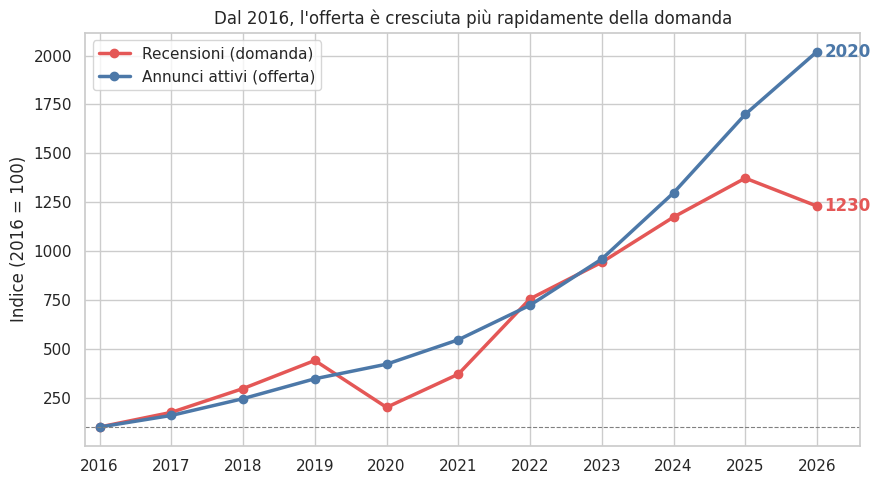

In [ ]:
START_YEAR = 2016
END_YEAR = 2026

trend["reviews_per_listing"] = (trend["reviews"] / trend["cumulative_listings"]).round(1)
print(trend.loc[START_YEAR:END_YEAR, ["reviews", "cumulative_listings", "reviews_per_listing"]])

base = trend.loc[START_YEAR:END_YEAR, ["reviews", "cumulative_listings"]]
index = base / base.loc[START_YEAR] * 100

series = {
    "reviews": ("Recensioni (domanda)", COLOR_RED),
    "cumulative_listings": ("Annunci attivi (offerta)", COLOR_BLUE),
}

fig, ax = plt.subplots(figsize=(9, 5))
for col, (label, color) in series.items():
    ax.plot(index.index, index[col], marker="o", linewidth=2.5, color=color, label=label)
    ax.text(END_YEAR + 0.1, index[col].iloc[-1], f"{index[col].iloc[-1]:.0f}",
            color=color, fontweight="bold", va="center")

ax.axhline(100, color="gray", linewidth=0.8, linestyle="--")
ax.set_xticks(index.index)
ax.set_xlim(START_YEAR - 0.2, END_YEAR + 0.6)
ax.set_ylabel(f"Indice ({START_YEAR} = 100)")

# Title is derived from the data, so it can never contradict the chart
supply_end = index["cumulative_listings"].iloc[-1]
demand_end = index["reviews"].iloc[-1]
faster, slower = ("supply", "demand") if supply_end > demand_end else ("demand", "supply")
names = {"supply": ("l'offerta", "dell'offerta"), "demand": ("la domanda", "della domanda")}
ax.set_title(f"Dal {START_YEAR}, {names[faster][0]} è cresciuta più rapidamente {names[slower][1]}")

ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

**Interpretazione:** con base 2015 le recensioni (indice 3102) crescono un po' più degli annunci cumulati (2892), e il divario si restringe dal 2022. Con base 2019 la lettura si inverte (recensioni ×3,1, annunci ×4,9): la conclusione dipende dall'anno base.

**8.4 Stagionalità delle recensioni:** per ogni mese calcoliamo la quota delle recensioni dell'anno che cade in quel mese, e ne facciamo la media sugli anni completi 2023-2025. Con una distribuzione uniforme ogni mese varrebbe l'8,3%. Attenzione: la data di una recensione segue il soggiorno di qualche giorno o settimana, quindi i picchi sono leggermente in ritardo rispetto ai periodi di maggiore affluenza.

year   2023  2024  2025  mean
month                        
1       4.2   4.1   3.8   4.0
2       4.2   4.6   4.1   4.3
3       5.7   5.9   5.5   5.7
4       8.7   9.3   9.4   9.2
5      11.0  10.3  10.6  10.6
6      10.3  10.4  10.4  10.4
7      10.0  10.2  10.4  10.2
8      11.4  11.6  12.2  11.7
9      12.7  12.2  12.7  12.5
10     11.4  11.8  11.7  11.6
11      6.1   6.0   5.8   6.0
12      4.1   3.6   3.5   3.7


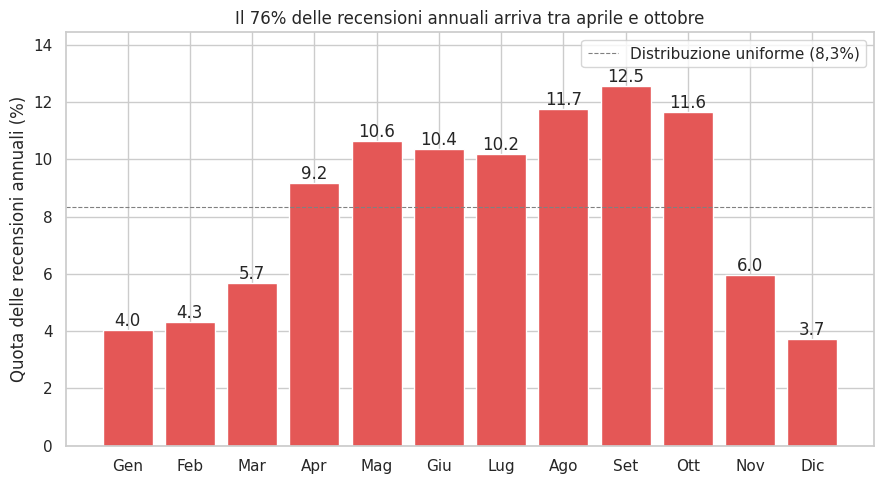

In [ ]:
reviews_catania["year"] = reviews_catania["date"].dt.year
reviews_catania["month"] = reviews_catania["date"].dt.month

full_years = [2023, 2024, 2025]
r = reviews_catania[reviews_catania["year"].isin(full_years)]

# Share of each year's reviews that falls in each month
monthly = r.groupby(["year", "month"]).size().unstack("year")
share = monthly / monthly.sum()
season = (share.mean(axis=1) * 100).reindex(range(1, 13))

print((share * 100).round(1).assign(mean=season.round(1)))

month_names = ["Gen", "Feb", "Mar", "Apr", "Mag", "Giu", "Lug", "Ago", "Set", "Ott", "Nov", "Dic"]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(month_names, season.values, color=COLOR_RED)   # rosso = recensioni (domanda), come in 8.3
ax.axhline(100 / 12, color="gray", linewidth=0.8, linestyle="--", label="Distribuzione uniforme (8,3%)")

for bar in bars:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
            f"{bar.get_height():.1f}", ha="center", va="bottom")

ax.set_ylabel("Quota delle recensioni annuali (%)")
ax.set_title("Il 76% delle recensioni annuali arriva tra aprile e ottobre")
ax.set_ylim(0, season.max() * 1.15)
ax.legend()
plt.tight_layout()
plt.show()

**Interpretazione:** il 76% delle recensioni arriva tra aprile e ottobre, con il picco a settembre (12,5%); gennaio, febbraio e dicembre restano sotto il 5%. Il profilo è lo stesso nel 2023, 2024 e 2025.

## 9. Distribuzione dei prezzi e outlier

**9.1 Ispezione dei prezzi:** guardiamo percentili, valori massimi e quota di annunci sotto alcune soglie per capire dove si concentra il mercato e se ci sono prezzi poco verosimili. Nessun dato viene modificato: la soglia degli outlier si decide dopo aver visto questi numeri.

In [ ]:
price = listings_catania["price"]

print("Missing prices:", price.isna().sum(), "| prices equal to 0:", (price == 0).sum())
print(price.describe().round(2))

print("\nPercentiles:")
print(price.quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 0.999]).round(2))

# Share of listings at or below some price thresholds
for t in [50, 100, 150, 200, 300, PRICE_CAP]:
    print(f"Share of listings at or below ${t}: {(price <= t).mean():.1%}")

# The 10 most expensive listings: are they plausible?
print("\nTop 10 prices:")
print(listings_catania.nlargest(10, "price")[["price", "room_type", "accommodates", "bedrooms", "number_of_reviews"]])

Missing prices: 385 | prices equal to 0: 0
count    4284.00
mean      118.11
std       124.07
min        10.12
25%        74.50
50%        95.00
75%       128.54
max      5623.07
Name: price, dtype: float64

Percentiles:
0.010      38.00
0.050      53.00
0.250      74.50
0.500      95.00
0.750     128.54
0.900     181.95
0.950     233.00
0.990     494.64
0.999    1125.05
Name: price, dtype: float64
Share of listings at or below $50: 3.6%
Share of listings at or below $100: 50.5%
Share of listings at or below $150: 76.0%
Share of listings at or below $200: 84.6%
Share of listings at or below $300: 89.2%
Share of listings at or below $494.64: 90.8%

Top 10 prices:
         price        room_type  accommodates  bedrooms  number_of_reviews
16731  5623.07  Entire home/apt             2       0.0                  1
27456  1812.00  Entire home/apt             4       1.0                  5
41191  1358.50  Entire home/apt            16       8.0                  6
48760  1180.00  Entire home/a

**9.2 Istogramma dei prezzi:** distribuzione dei prezzi per notte fino al 99° percentile (i pochi annunci oltre la soglia schiacciano il grafico e vengono mostrati solo nel conteggio). Mediana e media sono indicate per vedere quanto la coda alta sposta la media.

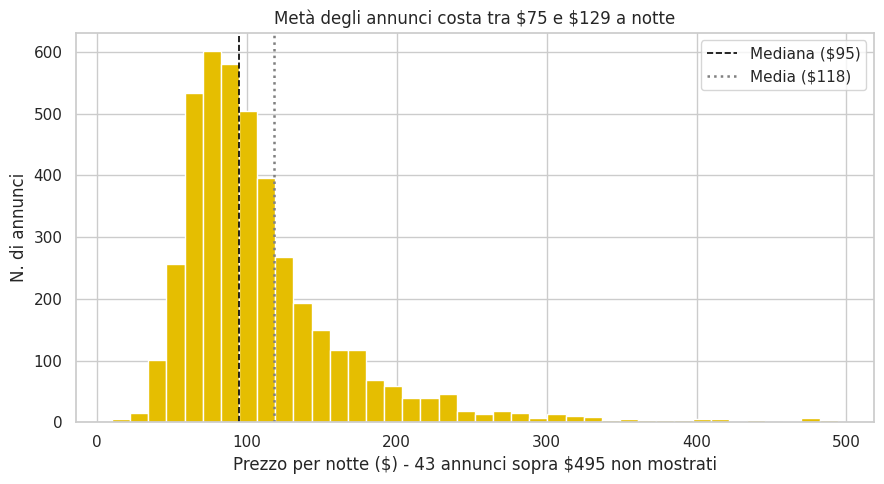

In [ ]:
n_above = (price > PRICE_CAP).sum()

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(price[price <= PRICE_CAP], bins=40, color=COLOR_YELLOW, edgecolor="white")
ax.axvline(price.median(), color="black", linestyle="--", linewidth=1.2, label=rf"Mediana (\${price.median():.0f})")
ax.axvline(price.mean(), color="gray", linestyle=":", linewidth=1.8, label=rf"Media (\${price.mean():.0f})")

ax.set_xlabel(rf"Prezzo per notte (\$) - {n_above} annunci sopra \${cap:.0f} non mostrati")
ax.set_ylabel("N. di annunci")
ax.set_title(r"Metà degli annunci costa tra \$75 e \$129 a notte")
ax.legend()
plt.tight_layout()
plt.show()

**Interpretazione:** la distribuzione è asimmetrica: la mediana è 95 USD e la media 118, spinta da una coda di annunci cari. Metà degli annunci costa tra 75 e 129 USD; i 43 annunci sopra 495 USD non sono mostrati.

**9.3 Annunci senza prezzo:** 385 annunci (8,2%) non hanno prezzo. Controlliamo se sono concentrati in certe tipologie, classi o tra gli annunci con disponibilità 0, perché in quel caso le statistiche sui prezzi rappresenterebbero solo una parte del mercato.

In [ ]:
no_price = listings_catania["price"].isna()
print(f"Listings without price: {no_price.sum()} ({no_price.mean():.1%})")

print("\nShare without price by room_type:")
print(listings_catania.groupby("room_type")["price"].apply(lambda s: s.isna().mean()).round(3))

print("\nShare without price by size_class:")
print(listings_catania.groupby("size_class", observed=True)["price"].apply(lambda s: s.isna().mean()).round(3))

zero_avail_bool = listings_catania["availability_365"] == 0
print(f"\nShare without price among listings with availability = 0: {no_price[zero_avail_bool].mean():.1%}")
print(f"Share without price among listings with availability > 0: {no_price[~zero_avail_bool].mean():.1%}")

no_reviews = listings_catania["number_of_reviews"] == 0
print(f"Share without price among listings with no reviews: {no_price[no_reviews].mean():.1%}")
print(f"Share without price among listings with reviews: {no_price[~no_reviews].mean():.1%}")

Listings without price: 385 (8.2%)

Share without price by room_type:
room_type
Entire home/apt    0.084
Hotel room         0.000
Private room       0.078
Shared room        0.250
Name: price, dtype: float64

Share without price by size_class:
size_class
small     0.072
medium    0.092
large     0.077
Name: price, dtype: float64

Share without price among listings with availability = 0: 46.9%
Share without price among listings with availability > 0: 4.6%
Share without price among listings with no reviews: 14.0%
Share without price among listings with reviews: 6.5%


**9.4 Outlier di prezzo:** marchiamo come outlier gli annunci sopra PRICE_CAP (494,64 USD) a notte (circa il 99° percentile) senza eliminarli, e confrontiamo i risultati con e senza di loro, come fatto per i casi sospetti.

In [ ]:
print(f"Outliers (price > {PRICE_CAP}):", listings_catania["price_outlier"].sum())
print(listings_catania.loc[listings_catania["price_outlier"], "room_type"].value_counts())

valid = listings_catania[listings_catania["price"].notna()].copy()
scenarios_price = {"all": valid, "without_outliers": valid[~valid["price_outlier"]]}

summary = pd.DataFrame({
    "n_prices": [len(d) for d in scenarios_price.values()],
    "mean_price": [d["price"].mean() for d in scenarios_price.values()],
    "median_price": [d["price"].median() for d in scenarios_price.values()]
}, index=list(scenarios_price.keys())).round(2).T
print("\nPrice summary:\n", summary)

by_class = pd.concat({
    name: d.groupby("size_class", observed=True)["price"].agg(["count", "mean", "median"])
    for name, d in scenarios_price.items()
}, axis=1).round(2)
print("\nPrice by size class:\n", by_class)

Outliers (price > 494.64): 43
room_type
Entire home/apt    39
Private room        4
Name: count, dtype: int64

Price summary:
                   all  without_outliers
n_prices      4284.00           4241.00
mean_price     118.11            110.38
median_price    95.00             95.00

Price by size class:
              all                 without_outliers                
           count    mean  median            count    mean  median
size_class                                                       
small       1386   97.21   82.50             1383   92.08   82.45
medium      1960  109.30   93.28             1945  103.66   93.00
large        938  167.39  136.00              913  152.40  134.00


**9.5 Fasce di prezzo:** dividiamo gli annunci in `budget` (fino a 75 USD), `mid` (75-150 USD) e `expensive` (oltre 150 USD) e controlliamo la quota di ciascuna fascia, tra gli annunci con prezzo disponibile.

In [ ]:
bins = [0, 75, 150, np.inf]
labels_price = ["budget", "mid", "expensive"]
listings_catania["price_band"] = pd.cut(listings_catania["price"], bins=bins, labels=labels_price)

print(listings_catania["price_band"].value_counts().reindex(labels_price))
print(listings_catania["price_band"].value_counts(normalize=True).reindex(labels_price).round(3))

price_band
budget       1121
mid          2428
expensive     735
Name: count, dtype: int64
price_band
budget       0.262
mid          0.567
expensive    0.172
Name: proportion, dtype: float64


**9.6 Distribuzione dei prezzi per classe:** boxplot dei prezzi per alloggi piccoli, medi e grandi (senza outlier oltre 500 USD), con la mediana indicata. È la versione grafica del confronto tra costi e dimensioni.

small: whisker limit ~170 USD | hidden above: 64 of 1383
medium: whisker limit ~184 USD | hidden above: 110 of 1945
large: whisker limit ~306 USD | hidden above: 53 of 913


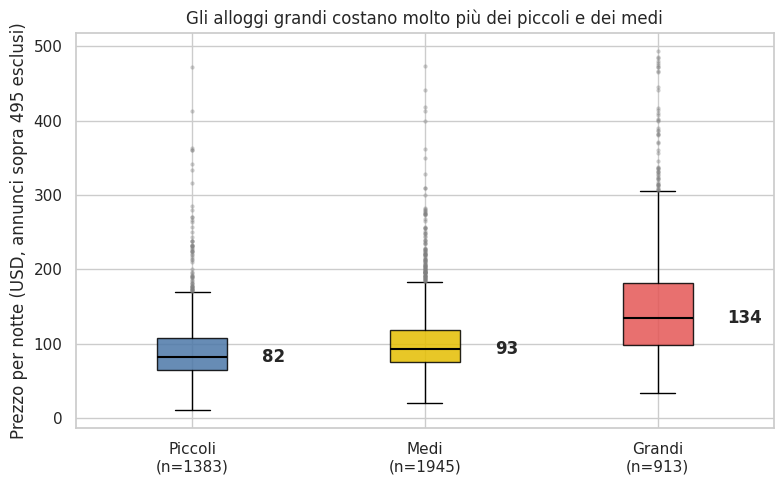

In [ ]:
valid = listings_catania[listings_catania["price"].notna() & ~listings_catania["price_outlier"]].copy()
classes = ["small", "medium", "large"]
size_colors = {"small": COLOR_BLUE, "medium": COLOR_YELLOW, "large": COLOR_RED}
data = [valid.loc[valid["size_class"] == c, "price"] for c in classes]

for c, d in zip(classes, data):
    q1, q3 = d.quantile([0.25, 0.75])
    limit = q3 + 1.5 * (q3 - q1)
    print(f"{c}: whisker limit ~{limit:.0f} USD | hidden above: {(d > limit).sum()} of {len(d)}")

fig, ax = plt.subplots(figsize=(8, 5))
bp = ax.boxplot(data, patch_artist=True, showfliers=True,
                flierprops={"marker": "o", "markersize": 3,
                            "markerfacecolor": "gray", "markeredgecolor": "none", "alpha": 0.4},
                medianprops={"color": "black", "linewidth": 1.5})
for patch, c in zip(bp["boxes"], classes):
    patch.set_facecolor(size_colors[c])
    patch.set_alpha(0.85)

# Median labels to the right of each box (boxes are 0.5 wide)
for i, d in enumerate(data, start=1):
    ax.text(i + 0.3, d.median(), f"{d.median():.0f}", va="center", fontweight="bold")

ax.set_xticklabels([f"{IT_CLASS[c]}\n(n={len(d)})" for c, d in zip(classes, data)])
ax.set_ylabel(f"Prezzo per notte (USD, annunci sopra {PRICE_CAP:.0f} esclusi)")
ax.set_title("Gli alloggi grandi costano molto più dei piccoli e dei medi")
plt.tight_layout()
plt.show()

**Interpretazione:** le mediane salgono da 82 a 93 a 134 USD: i grandi costano molto più di piccoli e medi, che sono vicini tra loro. Anche la dispersione dei grandi è più ampia (scatola da circa 100 a 180 USD).

**9.7 Fasce di prezzo per classe:** barre impilate al 100% con la quota di annunci economici, medi e costosi in ciascuna classe di dimensione.

price_band  budget   mid  expensive
size_class                         
small         39.5  53.2        7.3
medium        24.6  63.3       12.1
large          9.8  47.9       42.3


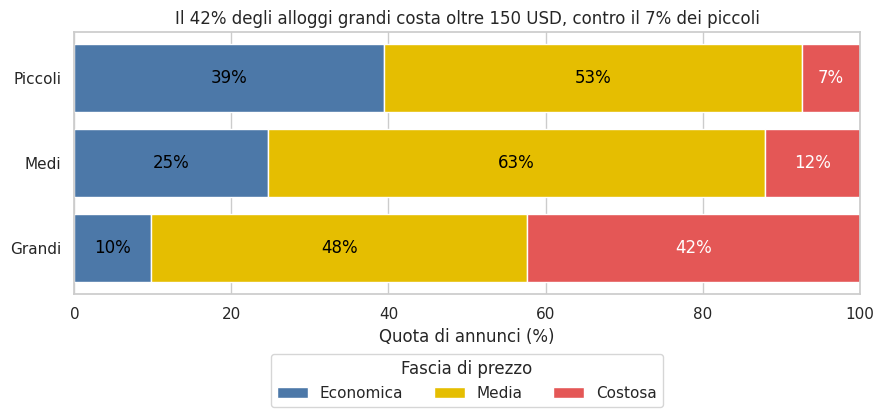

In [ ]:
labels_price = ["budget", "mid", "expensive"]
band_colors = {"budget": COLOR_BLUE, "mid": COLOR_YELLOW, "expensive": COLOR_RED}   # blu = economica, giallo = media, rosso = costosa
classes = ["small", "medium", "large"]

valid = listings_catania[listings_catania["price"].notna()]
share = (pd.crosstab(valid["size_class"], valid["price_band"], normalize="index")
           .reindex(index=classes, columns=labels_price) * 100)
print(share.round(1))

fig, ax = plt.subplots(figsize=(9, 4.5))
left = np.zeros(len(classes))
for band in labels_price:
    vals = share[band].values
    ax.barh([IT_CLASS[c] for c in classes], vals, left=left, color=band_colors[band], label=IT_BAND[band])
    for y, (l, v) in enumerate(zip(left, vals)):
        ax.text(l + v / 2, y, f"{v:.0f}%", ha="center", va="center",
                color="white" if band == "expensive" else "black")
    left += vals

ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Quota di annunci (%)")
ax.set_title("Il 42% degli alloggi grandi costa oltre 150 USD, contro il 7% dei piccoli")
ax.legend(title="Fascia di prezzo", ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.2))
plt.tight_layout()
plt.show()

**Interpretazione:** tra i grandi il 42% costa oltre 150 USD, contro il 12% dei medi e il 7% dei piccoli. All'opposto, il 39% dei piccoli è nella fascia economica contro il 10% dei grandi.

## 10. Contesto: Catania nel dataset regionale

**10.1 Quanti annunci e dove:** il dataset copre tutta la Sicilia e `neighbourhood_cleansed` indica il comune. Classifichiamo i 10 comuni con più annunci per collocare Catania.

Total listings: 56783 | municipalities: 376
Catania share of the dataset: 8.2%


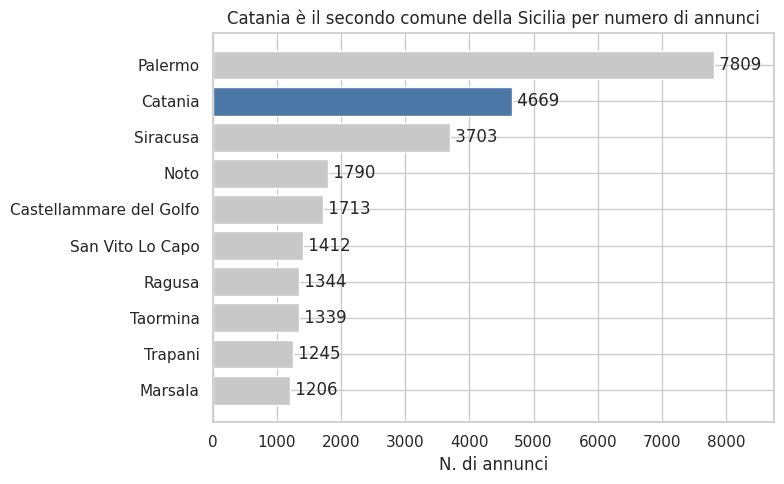

In [ ]:
counts_city = listings["neighbourhood_cleansed"].value_counts()
print(f"Total listings: {len(listings)} | municipalities: {counts_city.size}")
print(f"Catania share of the dataset: {counts_city['Catania'] / len(listings):.1%}")

top = counts_city.head(10)
bar_colors = [COLOR_BLUE if c == "Catania" else "#C8C8C8" for c in top.index]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(top.index, top.values, color=bar_colors)
ax.invert_yaxis()
for bar in bars:
    ax.text(bar.get_width(), bar.get_y() + bar.get_height() / 2,
            f" {int(bar.get_width())}", va="center")
ax.set_xlim(0, top.max() * 1.12)
ax.set_xlabel("N. di annunci")
ax.set_title("Catania è il secondo comune della Sicilia per numero di annunci")
plt.tight_layout()
plt.show()

**Interpretazione:** Catania è il secondo comune siciliano per annunci (4.669, l'8,2% del dataset di 56.783), dietro Palermo (7.809). Siracusa è terza con 3.703.

## 11. Composizione del mercato

**11.1 Tipologia di annuncio (`room_type`):** quanti annunci sono appartamenti interi, stanze private, camere d'albergo o stanze condivise. Per le tipologie mantengo gli stessi colori usati nell'analisi delle recensioni (verde e viola).

                 n_listings  share_%
room_type                           
Entire home/apt        3388     72.6
Private room           1274     27.3
Hotel room                3      0.1
Shared room               4      0.1


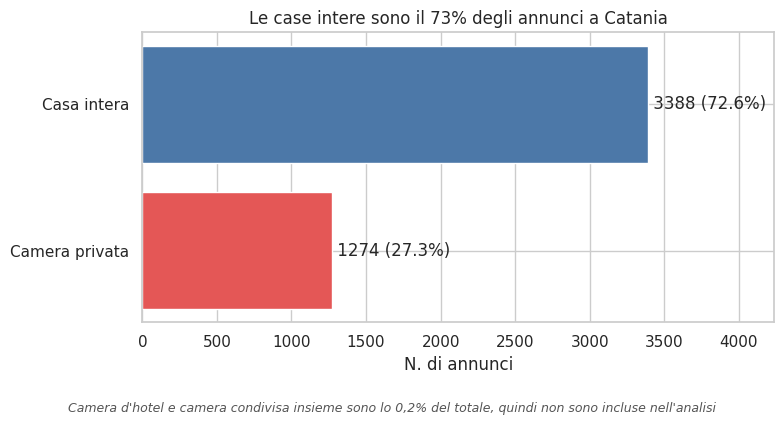

In [ ]:
room_order = ["Entire home/apt", "Private room", "Hotel room", "Shared room"]
room_colors = {"Entire home/apt": COLOR_BLUE, "Private room": COLOR_RED, "Hotel room": COLOR_YELLOW, "Shared room": COLOR_YELLOW}

counts = listings_catania["room_type"].value_counts().reindex(room_order)
share = counts / counts.sum() * 100
print(pd.DataFrame({"n_listings": counts, "share_%": share.round(1)}))

# Filtro per escludere i tipi di alloggio che rappresentano <= 0.5% della quota totale
threshold = 0.5
filtered_order = [r for r in room_order if share[r] > threshold]
filtered_counts = counts.reindex(filtered_order)
filtered_share = share.reindex(filtered_order)

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh([IT_ROOM[r] for r in filtered_order], filtered_counts.values, color=[room_colors[r] for r in filtered_order])
ax.invert_yaxis()
for bar, n, s in zip(bars, filtered_counts.values, filtered_share.values):
    ax.text(bar.get_width(), bar.get_y() + bar.get_height() / 2,
            f" {n} ({s:.1f}%)", va="center")

ax.set_xlim(0, filtered_counts.max() * 1.25)
ax.set_xlabel("N. di annunci")
ax.set_title(f"Le case intere sono il {share['Entire home/apt']:.0f}% degli annunci a Catania")

# Aggiunta della nota in pedice al grafico come didascalia
plt.figtext(0.5, -0.05, "Camera d'hotel e camera condivisa insieme sono lo 0,2% del totale, quindi non sono incluse nell'analisi",
            wrap=True, horizontalalignment='center', fontsize=9, style='italic', color='#555555')

plt.tight_layout()
plt.show()

**Interpretazione:** gli appartamenti interi sono il 72,6% degli annunci e le stanze private il 27,3%; hotel e stanze condivise sono 3 e 4 annunci in tutto. Per questo i confronti sulle recensioni tengono solo le prime due tipologie.

**11.2 Tipologia di proprietà (`property_type`):** guardiamo quante categorie ci sono, quali dominano e come si incrociano con `room_type`, prima di scegliere come raggrupparle per il grafico.

In [ ]:
prop = listings_catania["property_type"].value_counts()
print("Distinct property types:", prop.size)
print(prop.head(15))
print(f"\nTop 5 cover {prop.head(5).sum() / prop.sum():.1%} of listings")

# Top 8 types vs room_type (everything else grouped as "Other")
top8 = prop.head(8).index
grouped = listings_catania["property_type"].where(listings_catania["property_type"].isin(top8), "Other")
print("\n", pd.crosstab(grouped, listings_catania["room_type"]))

Distinct property types: 37
property_type
Entire rental unit                   1813
Entire home                           593
Private room in bed and breakfast     589
Entire condo                          529
Private room in rental unit           368
Entire vacation home                  325
Private room in condo                 120
Entire loft                            69
Private room in home                   53
Private room in vacation home          33
Room in hotel                          29
Tiny home                              22
Room in boutique hotel                 20
Private room in guesthouse             15
Private room in guest suite            14
Name: count, dtype: int64

Top 5 cover 83.4% of listings

 room_type                          Entire home/apt  Hotel room  Private room  \
property_type                                                                  
Entire condo                                   529           0             0   
Entire home                  

**11.3 Grafico delle proprietà:** le 8 tipologie più frequenti di `property_type` (le altre raggruppate in "Other"), colorate in base a `room_type`: verde per gli appartamenti interi, viola per le stanze private, grigio per il resto.

Property types without an Italian name: ['Entire vacation home']


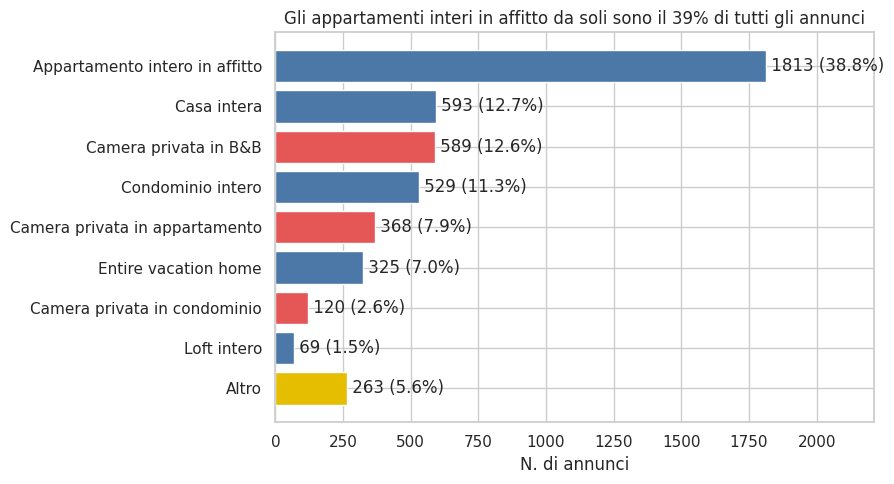

In [ ]:
top8 = prop.head(8).index
grouped = listings_catania["property_type"].where(listings_catania["property_type"].isin(top8), "Other")

counts_p = grouped.value_counts()
order = [c for c in counts_p.index if c != "Other"] + ["Other"]   # "Other" always last
counts_p = counts_p.reindex(order)

def bar_color(name):
    if name.startswith("Entire"):
        return COLOR_BLUE      # stesso blu di Entire home/apt
    if name.startswith("Private"):
        return COLOR_RED      # stesso rosso di Private room
    return COLOR_YELLOW

labels_p = [IT_PROP.get(n, n.replace("bed and breakfast", "B&B")) for n in counts_p.index]
print("Property types without an Italian name:", [n for n in counts_p.index if n not in IT_PROP])
share_p = counts_p / counts_p.sum() * 100

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(labels_p, counts_p.values, color=[bar_color(n) for n in counts_p.index])
ax.invert_yaxis()
for bar, n, s in zip(bars, counts_p.values, share_p.values):
    ax.text(bar.get_width(), bar.get_y() + bar.get_height() / 2,
            f" {n} ({s:.1f}%)", va="center")

ax.set_xlim(0, counts_p.max() * 1.22)
ax.set_xlabel("N. di annunci")
ax.set_title(f"Gli appartamenti interi in affitto da soli sono il {share_p['Entire rental unit']:.0f}% di tutti gli annunci")
plt.tight_layout()
plt.show()

**Interpretazione:** l'appartamento in affitto intero è la tipologia più diffusa (38,8%); tra le stanze, la prima è la stanza privata in B&B (12,6%). Le prime cinque tipologie coprono l'83,4% degli annunci.

**11.4 Ispezione delle amenities:** la colonna `amenities` contiene una lista in formato testo. La convertiamo in insiemi di servizi, contiamo quali sono più frequenti e cerchiamo i nomi esatti dei servizi citati dalla guida (Wi-Fi, aria condizionata, cucina, lavatrice, parcheggio, piscina, vista mare, self check-in). Nessun dato viene modificato.

In [ ]:
def parse_amenities(x):
    try:
        return set(json.loads(x))
    except (TypeError, ValueError):
        return set()

amen = listings_catania["amenities"].apply(parse_amenities)
print("Listings with no amenities listed:", (amen.apply(len) == 0).sum())
print("Median amenities per listing:", amen.apply(len).median())

counts_am = pd.Series([a for s in amen for a in s]).value_counts()
print("Distinct amenities:", counts_am.size)

print("\nTop 40 (% of listings):")
print((counts_am.head(40) / len(listings_catania) * 100).round(1))

# Exact names for the services mentioned in the guide
for kw in ["wifi", "air conditioning", "kitchen", "washer", "parking", "pool", "view", "self check-in"]:
    print(f"\n'{kw}':")
    print(counts_am[counts_am.index.str.contains(kw, case=False)].head(8))

Listings with no amenities listed: 3
Median amenities per listing: 33.0
Distinct amenities: 1456

Top 40 (% of listings):
Wifi                                     91.0
Hair dryer                               84.2
Kitchen                                  79.9
Hot water                                78.5
Air conditioning                         77.2
TV                                       73.1
Bed linens                               72.4
Hangers                                  71.6
Refrigerator                             66.4
Essentials                               66.2
Dishes and silverware                    65.1
Iron                                     61.9
Cooking basics                           60.4
Shampoo                                  59.4
Bidet                                    59.3
Fire extinguisher                        55.9
Heating                                  55.1
Hot water kettle                         53.3
Dedicated workspace                      51.3
Free

**11.5 Flag delle amenities:** creiamo una colonna True/False per ciascuno dei servizi citati dalla guida, usando i nomi esatti trovati in 11.4. Alcune scelte: la lavastoviglie non è una lavatrice, il "pocket wifi" non è il Wi-Fi dell'alloggio, "pool" non include "Whirlpool" né "Pool table", e la vista mare è solo "Sea view". Le percentuali sono calcolate sugli annunci con amenities dichiarate.

In [ ]:
flag_defs = {
    "has_wifi":       ("Wi-Fi",            r"^(fast )?wifi"),
    "has_ac":         ("Air conditioning", r"air conditioning"),
    "has_kitchen":    ("Kitchen",          r"^kitchen(ette)?$"),
    "has_washer":     ("Washer",           r"^(free |paid )?washer"),
    "has_parking":    ("Parking (any)",    r"parking"),
    "has_free_parking": ("Free parking",   r"^free .*parking"),
    "has_pool":       ("Pool",             r"(?<![a-z])pool(?! table| view)"),
    "has_sea_view":   ("Sea view",         r"^sea view$"),
    "has_self_checkin": ("Self check-in",  r"^self check-in$"),
}

def has(pattern):
    rx = re.compile(pattern, flags=re.I)
    return amen.apply(lambda s: any(rx.search(a) for a in s))

for col, (label, pattern) in flag_defs.items():
    listings_catania[col] = has(pattern)

with_am = amen.apply(len) > 0
print(f"Listings with amenities declared: {with_am.sum()} of {len(listings_catania)}")

amenity_share = pd.DataFrame({
    "amenity": [lab for lab, _ in flag_defs.values()],
    "n_listings": [int(listings_catania.loc[with_am, c].sum()) for c in flag_defs],
    "share_%": [round(listings_catania.loc[with_am, c].mean() * 100, 1) for c in flag_defs],
}).sort_values("share_%", ascending=False).reset_index(drop=True)
print(amenity_share)

# Broader definition of sea view, for reference
water_view = has(r"^(sea|beach|bay|harbor) view$")
print(f"\nSea/beach/bay/harbor view: {int(water_view[with_am].sum())} ({water_view[with_am].mean():.1%})")

Listings with amenities declared: 4666 of 4669
            amenity  n_listings  share_%
0             Wi-Fi        4518     96.8
1  Air conditioning        3916     83.9
2           Kitchen        3780     81.0
3     Parking (any)        3267     70.0
4            Washer        2561     54.9
5      Free parking        2229     47.8
6     Self check-in        2154     46.2
7          Sea view         112      2.4
8              Pool          42      0.9

Sea/beach/bay/harbor view: 145 (3.1%)


**11.6 Grafico delle amenities:** quota di annunci che offrono ciascun servizio, tra quelli con amenities dichiarate (4666 su 4669). Tra parentesi il numero di annunci.

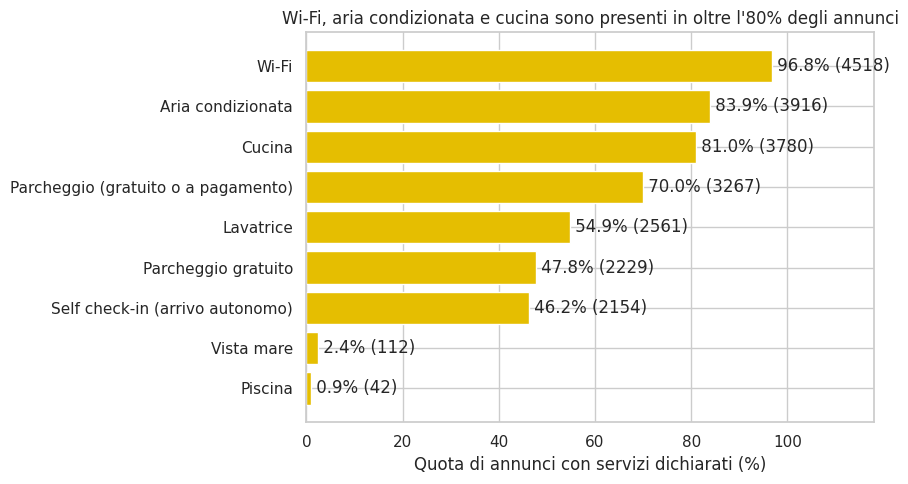

In [ ]:
data = amenity_share.copy()
data["amenity"] = data["amenity"].map(IT_AMENITY).fillna(data["amenity"])

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(data["amenity"], data["share_%"], color=COLOR_YELLOW)
ax.invert_yaxis()
for bar, n, s in zip(bars, data["n_listings"], data["share_%"]):
    ax.text(bar.get_width(), bar.get_y() + bar.get_height() / 2,
            f" {s:.1f}% ({n})", va="center")

ax.set_xlim(0, 118)
ax.set_xlabel("Quota di annunci con servizi dichiarati (%)")
ax.set_title("Wi-Fi, aria condizionata e cucina sono presenti in oltre l'80% degli annunci")
plt.tight_layout()
plt.show()

**Interpretazione:** Wi-Fi (96,8%), aria condizionata (83,9%) e cucina (81,0%) sono quasi standard. Vista mare (2,4%) e piscina (0,9%) sono rarità.

## 12. Strutture che lavorano di più (ultimo anno)

**12.1 Recensioni dell'ultimo anno:** contiamo, per ogni annuncio, le recensioni ricevute negli ultimi 12 mesi. La finestra termina all'ultima recensione presente nel file. Le recensioni sono un proxy dell'attività, non dell'occupazione. Guardiamo quanti annunci sono attivi, la classifica e quanto il lavoro è concentrato.

In [ ]:
# Window: last 12 months, ending at the most recent review in the file
last_date = reviews["date"].max()
start_date = last_date - pd.DateOffset(years=1)
print(f"Window: {start_date.date()} -> {last_date.date()}")

recent = reviews_catania[reviews_catania["date"] > start_date]
reviews_ly = recent.groupby("listing_id").size().rename("reviews_last_year")

listings_catania["reviews_last_year"] = (
    listings_catania["id"].map(reviews_ly).fillna(0).astype(int)
)

active = listings_catania["reviews_last_year"] > 0
print(f"Listings with at least 1 review in the window: {active.sum()} of {len(listings_catania)} ({active.mean():.1%})")
print(listings_catania.loc[active, "reviews_last_year"].describe().round(2))

# Concentration: share of last-year reviews coming from the top 10% of listings
sorted_r = listings_catania["reviews_last_year"].sort_values(ascending=False)
top10 = sorted_r.head(int(len(sorted_r) * 0.10)).sum() / sorted_r.sum()
print(f"\nTop 10% of listings -> {top10:.1%} of last-year reviews")

# Top 15 listings
print("\nTop 15 listings by reviews in the last year:")
print(listings_catania.nlargest(15, "reviews_last_year")
      [["id", "name", "room_type", "size_class", "accommodates", "price", "reviews_last_year"]])

# By room type and size class
for col in ["room_type", "size_class"]:
    g = listings_catania.groupby(col, observed=True)["reviews_last_year"]
    act = listings_catania[active].groupby(col, observed=True)["reviews_last_year"]
    print(f"\n--- {col} ---")
    print(pd.DataFrame({"n": g.size(), "median_all": g.median(),
                        "median_active": act.median(),
                        "share_active": g.apply(lambda s: (s > 0).mean()).round(3)}))

# Cross-check with the column provided by Inside Airbnb (if present)
if "number_of_reviews_ltm" in listings_catania.columns:
    diff = listings_catania["number_of_reviews_ltm"] - listings_catania["reviews_last_year"]
    print(f"\nSame as number_of_reviews_ltm: {(diff == 0).mean():.1%} | median absolute difference: {diff.abs().median()}")

Window: 2025-09-28 -> 2026-09-28
Listings with at least 1 review in the window: 2696 of 4669 (57.7%)
count    2696.00
mean       14.75
std        17.48
min         1.00
25%         3.00
50%         8.00
75%        21.00
max       134.00
Name: reviews_last_year, dtype: float64

Top 10% of listings -> 53.4% of last-year reviews

Top 15 listings by reviews in the last year:
                        id                                               name  \
18490             48660404                                       Petit palace   
44296  1431854085616485085             "Savio House" - Catania, Savio House 1   
44837  1435610025185392438             "Savio House" - Catania, Savio House 4   
18837             49015082                                         Maras’home   
44320  1439686994798487150     Loft moderno luminoso in cortile tipico centro   
16482             44679420  Homestay Rooftop | Etna view | guesthouse old ...   
44317  1431916270913037081                                 

**12.2 Strutture escluse:** togliamo gli annunci la cui prima e ultima recensione cadono entrambe prima di una data soglia (inizio dell'ultimo anno), cioè le strutture ferme da più di 12 mesi. Non cancelliamo le righe: usiamo un flag. Verifichiamo anche quanto cambia il risultato spostando la soglia.

In [ ]:
CUTOFF = start_date  # beginning of the last-year window (change here if the rule differs)

never_reviewed = listings_catania["first_review"].isna()

# Inactive: first AND last review both before the cutoff
listings_catania["inactive"] = (
    (listings_catania["first_review"] < CUTOFF) & (listings_catania["last_review"] < CUTOFF)
)

print(f"Cutoff: {CUTOFF.date()}")
print(f"Never reviewed:         {never_reviewed.sum()}")
print(f"Inactive (excluded):    {listings_catania['inactive'].sum()}")
print(f"Active in the window:   {(listings_catania['reviews_last_year'] > 0).sum()}")

listings_active = listings_catania[~listings_catania["inactive"] & ~never_reviewed].copy()
print(f"\nListings kept: {len(listings_active)} of {len(listings_catania)}")
print(f"Of which with 0 reviews in the window: {(listings_active['reviews_last_year'] == 0).sum()}")

# Sensitivity: how many listings are excluded with a different cutoff?
for years in [1, 2, 3]:
    c = last_date - pd.DateOffset(years=years)
    n = ((listings_catania["first_review"] < c) & (listings_catania["last_review"] < c)).sum()
    print(f"Cutoff {c.date()} ({years} y before the last review): {n} excluded")

Cutoff: 2025-09-28
Never reviewed:         1093
Inactive (excluded):    872
Active in the window:   2696

Listings kept: 2704 of 4669
Of which with 0 reviews in the window: 8
Cutoff 2025-09-28 (1 y before the last review): 872 excluded
Cutoff 2024-09-28 (2 y before the last review): 481 excluded
Cutoff 2023-09-28 (3 y before the last review): 269 excluded


**12.3 Heatmap:** ogni annuncio attivo pesa per il numero di recensioni dell'ultimo anno, quindi le zone più calde sono quelle dove le strutture lavorano di più. Da questa mappa si vede dove sta il centro della distribuzione, che useremo al punto 4.

In [ ]:
# Only listings with reviews in the window, no missing coordinates
heat_data = listings_active.dropna(subset=["latitude", "longitude", "reviews_last_year"]).copy()
heat_data = heat_data[heat_data["reviews_last_year"] > 0]
w = heat_data["reviews_last_year"]

# Cap computed on active listings only, so the center does not saturate
cap = w.quantile(0.95)
heat_data["weight"] = w.clip(upper=cap) / cap

# Numerical check: is the weighted centroid Piazza Duomo?
c_lat = np.average(heat_data["latitude"], weights=w)
c_lon = np.average(heat_data["longitude"], weights=w)
print(f"Weighted centroid: {c_lat:.5f}, {c_lon:.5f} "
      f"({haversine_km(c_lat, c_lon, CENTER_LAT, CENTER_LON):.2f} km from Piazza Duomo)")

inside = haversine_km(heat_data["latitude"], heat_data["longitude"], CENTER_LAT, CENTER_LON) <= RADIUS_KM
print(f"Within {RADIUS_KM} km: {inside.mean():.0%} of listings, {w[inside].sum() / w.sum():.0%} of reviews")
print(w.groupby(inside).agg(["count", "mean", "median"]))

# Map
m = folium.Map(location=[CENTER_LAT, CENTER_LON], zoom_start=13, tiles=None)
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}",
    attr="Esri", name="Esri Street Map"
).add_to(m)

folium.Circle([CENTER_LAT, CENTER_LON], radius=RADIUS_KM * 1000,
              color="black", weight=2, dash_array="6", fill=False,
              tooltip=f"Centro ({RADIUS_KM} km da Piazza Duomo)").add_to(m)

HeatMap(heat_data[["latitude", "longitude", "weight"]].values.tolist(),
        radius=12, blur=15, min_opacity=0.25, name="Mappa di calore dell'attività").add_to(m)

folium.Marker([CENTER_LAT, CENTER_LON], tooltip="Piazza Duomo",
              icon=folium.Icon(color="black", icon="star")).add_to(m)
folium.Marker([c_lat, c_lon], tooltip="Centroide pesato (recensioni dell'ultimo anno)",
              icon=folium.Icon(color="blue", icon="info-sign")).add_to(m)

m.get_root().html.add_child(folium.Element(
    "<style>.leaflet-tile-pane{filter:grayscale(100%);-webkit-filter:grayscale(100%);}</style>"))
folium.LayerControl(collapsed=False).add_to(m)
m

Weighted centroid: 37.50491, 15.08653 (0.26 km from Piazza Duomo)
Within 1.5 km: 80% of listings, 85% of reviews
       count       mean  median
False    541  11.120148     6.0
True    2155  15.658005     9.0


**Interpretazione:** il centroide pesato per le recensioni dell'ultimo anno cade a 0,26 km da Piazza Duomo, quindi il centro di attività coincide quasi con il centro storico. Entro 1,5 km c'è l'80% degli annunci attivi e l'85% delle recensioni.

**12.4 Nuovo centro:** usiamo come nuovo centro il centroide pesato calcolato in 12.3 (pesi = recensioni dell'ultimo anno). Servirà come riferimento per le mappe annuali.

In [ ]:
# New center = weighted centroid computed in 12.3
NEW_LAT, NEW_LON = c_lat, c_lon
print(f"New center: {NEW_LAT:.5f}, {NEW_LON:.5f} "
      f"({haversine_km(NEW_LAT, NEW_LON, CENTER_LAT, CENTER_LON):.2f} km from Piazza Duomo)")

New center: 37.50491, 15.08653 (0.26 km from Piazza Duomo)


**12.5 Mappe annuali (2011-2026): strutture attive e recensioni per anno**

Per ciascun anno presente nel dataset `review`, generiamo una mappa con lo sfondo Esri desaturato che mostra la distribuzione delle strutture attive. Ogni struttura è rappresentata da un pallino colorato in base alla sua `size_class` e con un raggio proporzionale alle recensioni ottenute in quell'anno.

In [ ]:
reviews['year'] = reviews['date'].dt.year
anni_disponibili = sorted(reviews['year'].dropna().astype(int).unique())

class_colors = {"small": COLOR_BLUE, "medium": COLOR_YELLOW, "large": COLOR_RED}

mappa = folium.Map(location=[NEW_LAT, NEW_LON], zoom_start=13, tiles=None)

folium.TileLayer(
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}',
    attr='Esri', name='Esri Street Map'
).add_to(mappa)

mappa.get_root().html.add_child(folium.Element(grayscale_css))      # grayscale_css definito al punto 6

folium.Circle(
    [NEW_LAT, NEW_LON], radius=RADIUS_KM * 1000,
    color="black", weight=2, dash_array="6", fill=False,
    tooltip=f"Nuovo Centro ({RADIUS_KM} km)"
).add_to(mappa)

layer_names = {}   # {anno_str: {classe: nome della variabile JS del layer}}
conteggi = {}      # {anno_str: numero strutture}
anni_validi = []

for anno in anni_disponibili:
    review_anno = reviews[reviews['year'] == anno]
    conteggio_anno = review_anno.groupby('listing_id').size().reset_index(name='review_count')

    strutture_anno = conteggio_anno.merge(
        listings_catania[['id', 'latitude', 'longitude', 'size_class', 'price']],
        left_on='listing_id', right_on='id', how='inner'
    ).dropna(subset=["latitude", "longitude", "size_class"])

    if strutture_anno.empty:
        continue

    anno_str = str(anno)
    anni_validi.append(anno)
    conteggi[anno_str] = len(strutture_anno)
    layer_names[anno_str] = {}

    for cls in ["medium", "small", "large"]:
        # show=False: il layer esiste ma non è sulla mappa; lo accende il JS
        layer = folium.FeatureGroup(name=f"{cls} ({anno})", show=False, control=False)
        dati_classe = strutture_anno[strutture_anno["size_class"] == cls]

        for _, row in dati_classe.iterrows():
            price_txt = f"${row['price']:.0f}" if pd.notna(row['price']) else "n.d."
            raggio_dinamico = 2.5 + (row['review_count'] * 0.15)

            folium.CircleMarker(
                location=[row['latitude'], row['longitude']],
                radius=raggio_dinamico,
                color=class_colors[cls], fill=True, fill_color=class_colors[cls],
                fill_opacity=0.6, weight=0.5,
                popup=f"Anno: {anno}<br>Classe: {IT_CLASS[cls]}<br>Prezzo: {price_txt}<br>Recensioni: {row['review_count']}",
            ).add_to(layer)

        layer.add_to(mappa)
        layer_names[anno_str][cls] = layer.get_name()

# --- UI: legenda con filtro classi (sostituisce LayerControl) + frecce anno ---
ui_html = """
<div style="position: fixed; bottom: 30px; left: 30px; z-index: 9999; background: white;
            padding: 8px 12px; border: 1px solid #999; font-size: 13px;">
  <b>Classe di dimensione</b><br>
  <label><input type="checkbox" data-cls="small" checked>
    <span style="color:__C_SMALL__;">&#9679;</span> piccoli (1-2 ospiti)</label><br>
  <label><input type="checkbox" data-cls="medium" checked>
    <span style="color:__C_MEDIUM__;">&#9679;</span> medi (3-4 ospiti)</label><br>
  <label><input type="checkbox" data-cls="large" checked>
    <span style="color:__C_LARGE__;">&#9679;</span> grandi (5+ ospiti)</label>
</div>

<div style="position: fixed; bottom: 30px; right: 30px; z-index: 9999; background: white;
            padding: 6px 10px; border: 1px solid #999; font-size: 14px;
            display: flex; align-items: center; gap: 10px;">
  <button id="prev-year" style="cursor:pointer; font-size:16px;">&larr;</button>
  <span id="year-label" style="min-width: 130px; text-align: center;"></span>
  <button id="next-year" style="cursor:pointer; font-size:16px;">&rarr;</button>
</div>

<script>
window.addEventListener('load', function () {
  var map    = window["__MAP__"];
  var layers = __LAYERS__;
  var counts = __COUNTS__;
  var years  = __YEARS__;
  var idx    = years.length - 1;           // parte dall'ultimo anno
  var active = {small: true, medium: true, large: true};
  var prev = document.getElementById('prev-year');
  var next = document.getElementById('next-year');

  function render() {
    var y = String(years[idx]);
    Object.keys(layers).forEach(function (yr) {
      Object.keys(layers[yr]).forEach(function (cls) {
        var lyr = window[layers[yr][cls]];
        var visible = (yr === y) && active[cls];
        if (visible && !map.hasLayer(lyr)) map.addLayer(lyr);
        if (!visible && map.hasLayer(lyr)) map.removeLayer(lyr);
      });
    });
    document.getElementById('year-label').innerHTML =
      '<b>' + y + '</b><br><small>' + counts[y] + ' strutture attive</small>';
    prev.disabled = (idx === 0);
    next.disabled = (idx === years.length - 1);
  }

  prev.onclick = function () { if (idx > 0) { idx--; render(); } };
  next.onclick = function () { if (idx < years.length - 1) { idx++; render(); } };

  document.querySelectorAll('input[data-cls]').forEach(function (cb) {
    cb.onchange = function () { active[cb.dataset.cls] = cb.checked; render(); };
  });

  render();
});
</script>
"""

ui_html = (ui_html
    .replace("__C_SMALL__", class_colors["small"])
    .replace("__C_MEDIUM__", class_colors["medium"])
    .replace("__C_LARGE__", class_colors["large"])
    .replace("__MAP__", mappa.get_name())
    .replace("__LAYERS__", json.dumps(layer_names))
    .replace("__COUNTS__", json.dumps(conteggi))
    .replace("__YEARS__", json.dumps([int(a) for a in anni_validi])))

mappa.get_root().html.add_child(folium.Element(ui_html))

display(mappa)

**Interpretazione:** scorrendo gli anni le recensioni crescono da 2.598 nel 2016 a 35.671 nel 2025, e i pallini si moltiplicano. Il raggio di ciascun pallino indica quante recensioni ha ricevuto l'annuncio in quell'anno.

## 13. Lettura Conclusiva
L'analisi degli annunci Airbnb di Catania (4.669 annunci, dati Inside Airbnb) porta a cinque insight principali.

1. Il mercato è dominato dagli appartamenti interi, con servizi di base quasi universali. Il 72,6% degli annunci è un appartamento intero, il 27,3% una stanza privata; hotel e camere condivise sono trascurabili. Le stanze private lavorano meno: il 41,3% non ha recensioni (contro il 16,7% degli appartamenti interi). I servizi più comuni sono Wi-Fi (96,8%), aria condizionata (83,9%) e cucina (81,0%).

2. Il turismo si concentra nel centro, ma il centro costa solo poco di più. Circa il 61% degli annunci è entro 1 km da Piazza Duomo e circa il 78% delle recensioni arriva da lì. La densità scende da 1.510 annunci/km² nei primi 500 m a 45 annunci/km² tra 1,5 e 2,5 km. A parità di classe dimensionale il sovrapprezzo mediano del centro (raggio 1,5 km) è modesto: +5,4% piccoli, +2,2% medi, +8,1% grandi. Sale a +10-16% nel nucleo entro 500 m, ma non è stabile: cambia con il raggio (per i grandi va da +1,5% a 1 km a +9,8% a 2 km) e con la media quasi sparisce (da −1% a +3% senza outlier). Pesando gli annunci attivi per le recensioni dell'ultimo anno, il centro di attività cade a 0,26 km da Piazza Duomo, ed entro 1,5 km ci sono l'80% degli annunci attivi e l'85% delle recensioni.

3. La dimensione fa il prezzo, ma sulla performance il quadro è meno netto. Il prezzo mediano per notte (senza annunci sopra 500 USD) sale da 82 USD (piccoli) a 93 (medi) a 134 (grandi), e il 42% dei grandi costa oltre 150 USD contro il 7% dei piccoli. Sulle recensioni mensili il risultato dipende da come si trattano gli annunci senza recensioni: includendoli i grandi risultano più attivi (mediana 0,50 contro 0,26 dei piccoli), ma pesa il fatto che il 30% dei piccoli non ha recensioni contro il 16% dei grandi. Guardando solo gli annunci con almeno una recensione, i grandi non hanno alcun vantaggio (0,78 piccoli, 0,76 medi, 0,68 grandi).

4. Dal 2015 la domanda cresce un po' più dell'offerta, ma dal 2022 è l'offerta a correre, e il mercato è fortemente stagionale. Dal 2015 al 2025 le recensioni crescono di ×31,0 e gli annunci cumulati (contati dall'anno della prima recensione) di ×28,9: con 2015 = 100 si arriva a 3.102 per la domanda e a 2.892 per l'offerta. Il rapporto però non è stabile: le recensioni per annuncio passano da 11,1 (2015) a 18,6 (2019), scendono a 7,0 nel 2020, risalgono a 15,3 nel 2022 e calano a 11,9 nel 2025, perché dal 2022 gli annunci crescono di ×2,35 e le recensioni di ×1,8. Il 76% delle recensioni arriva tra aprile e ottobre, con il picco a settembre (12,5%); il pattern è identico nel 2023, 2024 e 2025.

5. Le strutture che lavorano di più sono poche. Nell'ultimo anno (dal 28/09/2025 al 28/09/2026) 2.696 annunci su 4.669 (57,7%) hanno ricevuto almeno una recensione, con una mediana di 8; il 10% più attivo raccoglie il 53,4% delle recensioni. Sono considerati inattivi, e quindi esclusi, 872 annunci la cui ultima recensione risale a più di 12 mesi fa; altri 1.093 non hanno mai ricevuto recensioni. Gli appartamenti interi sono attivi molto più spesso delle stanze private (64,6% contro 39,7%).

Limiti. Le recensioni sono un proxy della domanda, non misurano occupazione né ricavi. I prezzi sono quelli al momento dello scraping, quindi dipendono dalla stagione. Il confronto centro/fuori centro è descrittivo, senza test statistici, e il raggio di 1,5 km è una stima.